# The Final System
Notebooks 01-06 each answered one part of the problem and ended with a recommendation. This notebook puts those recommendations together into **one system**, runs it end to end, and reports its results once. It is the reference for the report: every headline number of the project should be quoted from here.

**What each notebook hands to this one**

| Notebook | What it found | What this notebook takes |
|---|---|---|
| 01 | Hidden missing values, drifting columns, about 1% fraud, and applicants aged 50+ with 3.1x the fraud rate (section 4) | the reasons behind notebook 02's features |
| 02 | XGBoost, tuned on month 4, with a threshold that flags 5% of genuine applications on month 5 (sections 6-7); the protocol and the terms (sections 2 and 2.1) | the model recipe, the protocol, and the frozen model as the **current system** |
| 03 | Sending the alerts the model is least sure about to the 10 lowest-cost analysts is the cheapest review policy (section 6) | the review simulation, and that policy as the current review stage |
| 04 | Platt calibration on month 5 (section 7.3); a fixed alert rate keeps the FPR on target where the fixed threshold drifts (section 10); how results change with the fraud rate (section 8) | stages 2 and 3, and the fraud-rate check |
| 05 | What the frozen model relies on, and that its explanations are exact and stable (Summary) | a check that the final model relies on the same features (section 10 here) |
| 06 | The frozen model wrongly flags genuine applicants aged 50+ 3.3 times as often (predictive equality 0.31); reweighing repairs it to about 0.90 for about 2 points of recall (sections 7-9); a fair analyst pool lifts the review stage's fairness (section 10); the noise of one month's fairness ratio is 0.04 (section 11.2) | stage 1's mitigation, stage 4's analyst pool, and the monitoring trigger |

**The system**

| Stage | What it does | The choice |
|---|---|---|
| **1. Model** | scores every application | notebook 02's XGBoost recipe, trained on Base months 0-3 with **reweighing** at full strength: every training row is weighted so that being 50+ and being fraud are unrelated. `customer_age` stays an input |
| **2. Probabilities** | turns scores into a chance of fraud | a Platt calibrator fitted on Base month 5 |
| **3. Decision rule** | decides which applications are flagged | a **fixed alert rate**: each month, flag the same share of applications that the 5%-FPR threshold flagged on month 5 |
| **4. Review** | decides which flagged applications a human checks | the 50% of alerts the model is least sure about go to the **10 lowest-cost analysts among those with predictive equality of at least 0.8** on the history months; the model decides the rest |

The **current system** is notebook 02's frozen model with its fixed threshold, and notebook 03's review policy. It is the comparison throughout.

Outline:
1. Imports
2. Setup and functions
3. Data
4. Stage 1: the model
5. Stage 2: probabilities
6. Stage 3: the decision rule
7. Results on the Base test months
8. Robustness: the BAF variants and other fraud rates
9. Stage 4: human review (FiFAR)
10. Does notebook 05's picture still hold?
11. Known limits
12. Model card and monitoring
13. Summary

## **Decision Log: the Four Choices, and Which Saw the Test Months**
The protocol (months, seeds, metrics, the 5% FPR budget) is notebook 02's (section 2), and the terms are those of notebook 02, section 2.1: **recall** is the share of fraud the system flags at its operating point, **recall at 5% FPR** is the ranking quality of a model alone. Confidence intervals use notebook 04's bootstrap (section 5) and the cost ratios its grid (section 9). Nothing is chosen in this notebook: the four choices below were made earlier, and months 6-7 are reported once.

| Choice | Value | Set on | Was the test period seen when it was chosen? |
|---|---|---|---|
| Mitigation | reweighing at full strength (age 50+ vs under 50) | the weights: months 0-3. The choice: notebook 06, section 8.1, on **month 4** (at R = 10 it ties with equal-FPR group thresholds; reweighing is preferred because it needs no age-dependent cut-off) | **no** |
| Calibrator | Platt, one per seed | month 5; the method from notebook 04, section 7.3 | no |
| Decision rule | fixed alert rate | the rate: month 5. The rule: notebook 04, section 10 compared four rules on Base months 6-7 and the variants | **yes** (the rule, not the rate) |
| Review policy | 50% capacity; the 10 lowest-cost analysts with predictive equality at least 0.8 | the analysts: FiFAR history months 4-6. The 0.8: the four-fifths reference. The choice of a fair pool over notebook 03's cheapest pool: notebook 06, section 10, on **month 7** | **yes** (the policy, not the analysts) |

The values are all set on training, month-5 or history data, but two of the four *methods* were chosen after test results had been seen. A new month of data is the real test.

## **1. Imports**

In [1]:
import os
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
import xgboost as xgb

from model_loading import calibrate, load_model   # the frozen model and its calibrator (notebooks 02 and 04)

# Plot settings (same as notebooks 02-06): orange = current system, blue = final system throughout
BLUE = '#2a78d6'
ORANGE = '#eb6834'
GREEN = '#1baf7a'
GREY = '#8a8a8a'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['grid.alpha'] = 0.3

## **2. Setup**

In [2]:
DATA_DIR = '../data'
FIFAR_DIR = f'{DATA_DIR}/fifar'
CACHE_FILE = f'{DATA_DIR}/cache/final_system_scores.parquet'   # data/ is not committed, so neither is the cache
MODEL_DIR = '../outputs/models'
TARGET = 'fraud_bool'

TRAIN_MONTHS = [0, 1, 2, 3]
VALIDATION_MONTHS = [4]
CALIBRATION_MONTHS = [5]
TEST_MONTHS = [6, 7]
SEEDS = [0, 1, 2, 3, 4]
DEPLOYED_SEED = 0                  # the copy that would be deployed; the 5 seeds measure run-to-run variation

AGE_CUT = 50                       # the BAF group with a documented bias: customer_age of 50 or more
TARGET_FPR = 0.05                  # the project's budget: 5% of genuine applications flagged (on month 5)
REWEIGH_STRENGTH = 1.0             # full strength: group and label independent in the weighted training data
COST_RATIOS = [5, 10, 20, 50]      # the grid of notebook 04, section 9
MAIN_RATIO = 10
N_BOOTSTRAP = 1000                 # as notebooks 04 and 06
BOOTSTRAP_SEED = 4012              # as notebooks 04 and 06, so the same resampled applications are used
MIN_GROUP_ROWS = 1000              # as notebook 04, section 12
FOUR_FIFTHS = 0.8                  # the common adverse-impact reference for a ratio of rates
MONITOR_DROP = 0.04                # notebook 06, section 11.2: noise half-width (0.041) of one month's predictive equality

FA_HISTORY_MONTHS, FA_TEST_MONTHS = [4, 5, 6], [7]   # as notebook 03
REVIEW_CAPACITY = 0.5              # half of the alerts can be reviewed
POOL_SIZE = 10                     # as notebook 03
POOL_MIN_PE = 0.8                  # notebook 06, section 10: the four-fifths reference

os.makedirs(os.path.dirname(CACHE_FILE), exist_ok=True)

final_model = json.load(open('../configs/final_model.json'))
FEATURES = final_model['features']
PARAMS = dict(final_model['params'])
frozen_thresholds = {int(seed): t for seed, t in final_model['thresholds'].items()}
frozen_calibration = json.load(open('../configs/calibration.json'))

DATASET_FILES = {'base': 'Base.csv', 'variant_i': 'Variant I.csv', 'variant_ii': 'Variant II.csv',
                 'variant_iii': 'Variant III.csv', 'variant_iv': 'Variant IV.csv', 'variant_v': 'Variant V.csv'}
DATASETS = list(DATASET_FILES)
BASE_SCORE_MONTHS = [4, 5, 6, 7]   # validation, calibration and test months (FiFAR history and test too)
VARIANT_SCORE_MONTHS = [5, 6, 7]   # the variants on the threshold month and the test months

MISSING_AS_MINUS_ONE = ['prev_address_months_count', 'current_address_months_count',
                        'bank_months_count', 'session_length_in_minutes',
                        'device_distinct_emails_8w']

CATEGORY_LEVELS = {
    'payment_type': ['AA', 'AB', 'AC', 'AD', 'AE'],
    'employment_status': ['CA', 'CB', 'CC', 'CD', 'CE', 'CF', 'CG'],
    'housing_status': ['BA', 'BB', 'BC', 'BD', 'BE', 'BF', 'BG'],
    'source': ['INTERNET', 'TELEAPP'],
    'device_os': ['linux', 'macintosh', 'other', 'windows', 'x11'],
}
DRIFTING_COLUMNS = ['velocity_6h', 'velocity_24h', 'velocity_4w', 'zip_count_4w']
KEEP_COLUMNS = ['customer_age', 'income', 'employment_status', 'housing_status']

### **2.1 Functions Copied from Earlier Notebooks**
Copied unchanged, so that every number is computed exactly as in the notebook it comes from. The source is named in each function.

In [3]:
def preprocess(df, missing_flags=True):
    # Copied from notebook 02, section 3.
    X = df.copy()
    X['income'] = X['income'].round(1)

    for col in MISSING_AS_MINUS_ONE + ['intended_balcon_amount']:
        if col == 'intended_balcon_amount':
            is_missing = X[col] < 0      # any negative number means missing
        else:
            is_missing = X[col] == -1
        if missing_flags:
            X[f'{col}_missing'] = is_missing.astype(int)
        X.loc[is_missing, col] = np.nan

    for col, levels in CATEGORY_LEVELS.items():
        X[col] = pd.Categorical(X[col], categories=levels)

    return X.drop(columns=['device_fraud_count', 'x1', 'x2'], errors='ignore')


def make_features(df, missing_flags=False, drifting='keep', valid_phones=False, include_age=True):
    # Copied from notebook 02, section 4.2.
    X = preprocess(df, missing_flags)

    if valid_phones:
        X['valid_phones'] = X['phone_home_valid'] + X['phone_mobile_valid']

    if drifting == 'ratio':
        X['velocity_6h_vs_24h'] = X['velocity_6h'] / X['velocity_24h']
        X['velocity_24h_vs_4w'] = X['velocity_24h'] / X['velocity_4w']
        X['zip_count_vs_velocity_4w'] = X['zip_count_4w'] / X['velocity_4w']
    elif drifting == 'rank':
        for col in DRIFTING_COLUMNS:
            X[f'{col}_month_rank'] = X.groupby('month')[col].rank(pct=True)
    if drifting != 'keep':
        X = X.drop(columns=DRIFTING_COLUMNS)

    if not include_age:
        X = X.drop(columns=['customer_age'])

    return X.drop(columns=[TARGET, 'month'])


def threshold_at_fpr(y_true, scores, target_fpr=TARGET_FPR):
    # Copied from notebook 02, section 2.
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    i = np.searchsorted(fpr, target_fpr, side='right') - 1
    return thresholds[i]


def make_xgboost(seed):
    # Copied from notebook 02, section 4.1 (make_model for xgboost), with the frozen settings.
    settings = {'subsample': 0.8, 'colsample_bytree': 0.8, **PARAMS}
    return xgb.XGBClassifier(**settings, random_state=seed, tree_method='hist', enable_categorical=True)


def reweighing_weights(y, is_old, strength=1.0):
    # Copied from notebook 06, section 7.1.
    # Kamiran and Calders (2012): w(g, y) = P(g) P(y) / P(g, y), raised to the given strength.
    y, is_old = np.asarray(y), np.asarray(is_old)
    w = np.ones(len(y))
    for g in (True, False):
        for label in (0, 1):
            cell = (is_old == g) & (y == label)
            w[cell] = ((is_old == g).mean() * (y == label).mean() / cell.mean()) ** strength
    return w


def logit(p):
    # Copied from notebook 04, section 7 (the clipping of configs/calibration.json).
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def lowest_cost_threshold(y_true, scores_, ratio):
    # Copied from notebook 03, section 6.1.
    order = np.argsort(-scores_)
    sorted_scores = scores_[order]
    is_fraud = y_true[order] == 1
    false_alarms = np.cumsum(~is_fraud)
    missed_fraud = is_fraud.sum() - np.cumsum(is_fraud)
    costs = ratio * missed_fraud + false_alarms
    best = np.argmin(costs)
    if ratio * is_fraud.sum() <= costs[best]:
        return np.inf
    return sorted_scores[best]


def group_measures(D, y, old):
    # Copied from notebook 06, section 10.1: rates of one or many decision vectors (columns of D) by age group.
    D = np.asarray(D, dtype=float)
    if D.ndim == 1:
        D = D[:, None]
    g, f = y == 0, y == 1
    out = {'FPR 50+': D[g & old].mean(axis=0), 'FPR under 50': D[g & ~old].mean(axis=0),
           'recall 50+': D[f & old].mean(axis=0), 'recall under 50': D[f & ~old].mean(axis=0),
           'recall': D[f].mean(axis=0), 'FPR': D[g].mean(axis=0)}
    out['predictive equality'] = np.minimum(out['FPR 50+'], out['FPR under 50']) / np.maximum(out['FPR 50+'], out['FPR under 50'])
    out['equal opportunity'] = np.minimum(out['recall 50+'], out['recall under 50']) / np.maximum(out['recall 50+'], out['recall under 50'])
    out['equalised odds difference'] = np.maximum(np.abs(out['FPR 50+'] - out['FPR under 50']), np.abs(out['recall 50+'] - out['recall under 50']))
    return out


def at_fraud_rate(tpr, fpr, pi):
    # Copied from notebook 04, section 8.
    return {
        'precision': tpr * pi / (tpr * pi + fpr * (1 - pi)),
        'alerts per 10,000': 10_000 * (tpr * pi + fpr * (1 - pi)),
        'fraud caught per 10,000': 10_000 * tpr * pi,
        'false alarms per fraud caught': fpr * (1 - pi) / (tpr * pi),
    }

### **2.2 The Evaluation Function and Confidence Intervals**
Copied from notebook 06, section 7.3, with two measures added (**precision** and **alert rate**). `evaluate_flags` takes the flags of any number of systems (one set per seed) and returns, for each, the point estimate (row 0, the mean over seeds) and 1,000 Poisson-bootstrap resamples. All systems are evaluated on **the same resampling weights**, so the difference between two systems gets an interval that accounts for the pairing.

The group argument is any yes/no column: by default age 50+, but section 11 passes the second-tier groups. In the output, "50+" then means "in the group" and "under 50" means "not in the group".

In [4]:
def _metric_frame(c, t, n):
    # Copied from notebook 06, section 7.3; precision and alert rate added.
    # Flagged counts c and totals t (one row per resample), each with columns:
    # genuine, fraud, genuine 50+, genuine under 50, fraud 50+, fraud under 50, all 50+, all under 50.
    d = {}
    d['recall'] = c[:, 1] / t[:, 1]
    d['FPR'] = c[:, 0] / t[:, 0]
    d['precision'] = c[:, 1] / (c[:, 0] + c[:, 1])
    d['alert rate'] = (c[:, 0] + c[:, 1]) / n
    d['FPR 50+'], d['FPR under 50'] = c[:, 2] / t[:, 2], c[:, 3] / t[:, 3]
    d['TPR 50+'], d['TPR under 50'] = c[:, 4] / t[:, 4], c[:, 5] / t[:, 5]
    d['predictive equality'] = np.minimum(d['FPR 50+'], d['FPR under 50']) / np.maximum(d['FPR 50+'], d['FPR under 50'])
    d['equal opportunity'] = np.minimum(d['TPR 50+'], d['TPR under 50']) / np.maximum(d['TPR 50+'], d['TPR under 50'])
    d['FPR gap'] = np.abs(d['FPR 50+'] - d['FPR under 50'])
    missed = t[:, 1] - c[:, 1]
    d['false alarms per 1,000'] = 1000 * c[:, 0] / n
    d['false alarms per 1,000, 50+'] = 1000 * c[:, 2] / t[:, 6]
    d['false alarms per 1,000, under 50'] = 1000 * c[:, 3] / t[:, 7]
    for ratio in COST_RATIOS:
        d[f'cost per 10,000 (R={ratio})'] = 10_000 * (ratio * missed + c[:, 0]) / n
    return pd.DataFrame(d)


def evaluate_flags(y, is_old, candidates, n_resamples=N_BOOTSTRAP, rng_seed=BOOTSTRAP_SEED, batch=50):
    # Copied from notebook 06, section 7.3.
    # candidates: {name: {seed: flags}}. Returns {name: DataFrame}; row 0 is the real data, the others are Poisson resamples.
    # The resampling weights are the same for every candidate (and for every call with the same number of applications).
    y, is_old = np.asarray(y), np.asarray(is_old)
    fraud = y == 1
    masks = np.column_stack([~fraud, fraud, ~fraud & is_old, ~fraud & ~is_old, fraud & is_old, fraud & ~is_old, is_old, ~is_old]).astype(np.float32)
    rng = np.random.default_rng(rng_seed)
    parts = {name: [] for name in candidates}

    def add(W):
        totals, n = W @ masks, W.sum(axis=1)
        for name, flags_by_seed in candidates.items():
            counts = np.mean([W @ (masks * np.asarray(f)[:, None].astype(np.float32)) for f in flags_by_seed.values()], axis=0)
            parts[name].append(_metric_frame(counts, totals, n))

    add(np.ones((1, len(y)), dtype=np.float32))
    for start in range(0, n_resamples, batch):
        add(rng.poisson(1.0, size=(min(batch, n_resamples - start), len(y))).astype(np.float32))
    return {name: pd.concat(p, ignore_index=True) for name, p in parts.items()}


def with_interval(results, names, column):
    # Copied from notebook 06, section 7.3: estimate and 95% interval of one measure for several candidates.
    return pd.DataFrame({name: {'estimate': results[name].loc[0, column], 'CI low': results[name].loc[1:, column].quantile(0.025),
                                'CI high': results[name].loc[1:, column].quantile(0.975)} for name in names}).T


def paired_difference(results, name, reference, column):
    # Copied from notebook 06, section 7.3: name minus reference, with the interval of the paired resamples.
    diff = results[name][column] - results[reference][column]
    return {'difference': diff.iloc[0], 'CI low': diff.iloc[1:].quantile(0.025), 'CI high': diff.iloc[1:].quantile(0.975)}


def fmt(estimate, low, high, digits=3):
    return f'{estimate:.{digits}f} ({low:.{digits}f} to {high:.{digits}f})'

## **3. Data**
Base is read once. The second-tier groups are fixed by notebook 06's rule (section 2.1): for income, employment and housing, the value with the highest fraud rate in **training months 0-3** among values with at least 1,000 rows.

In [5]:
base_raw = pd.read_csv(f'{DATA_DIR}/Base.csv')
train_raw = base_raw[base_raw['month'].isin(TRAIN_MONTHS)]
print(f'Base: {len(base_raw):,} applications; training months {TRAIN_MONTHS}: {len(train_raw):,} applications, '
      f'fraud rate {train_raw[TARGET].mean():.2%}')

SECOND_TIER_COLUMNS = ['income', 'employment_status', 'housing_status']


def highest_fraud_value(column):
    # Copied from notebook 06, section 2.1.
    table = train_raw.groupby(column)[TARGET].agg(rows='size', fraud_rate='mean')
    table = table[table['rows'] >= MIN_GROUP_ROWS]
    return table['fraud_rate'].idxmax()


def in_group(frame, column, value):
    # Copied from notebook 06, section 2.1 (income is compared with a tolerance, as it is a decimal).
    if column == 'income':
        return pd.Series(np.isclose(frame[column].astype(float), float(value), atol=0.05), index=frame.index)
    return frame[column].eq(value)


SECOND_TIER = {}   # name -> (column, value)
for column in SECOND_TIER_COLUMNS:
    value = highest_fraud_value(column)
    SECOND_TIER[f'{column} = {value}'] = (column, value)
print('Second-tier groups:', list(SECOND_TIER))

Base: 1,000,000 applications; training months [0, 1, 2, 3]: 547,975 applications, fraud rate 0.97%
Second-tier groups: ['income = 0.9', 'employment_status = CC', 'housing_status = BA']


## **4. Stage 1: the Model**
### **4.1 The Reweighing Weights**
Every training application gets the weight P(group) x P(label) / P(group, label), with group = 50+ or under 50 (notebook 06, section 7.1). In the weighted data the fraud rate is the same in both groups, so the model can no longer learn "older means riskier" from the base rates. The weights multiply the fraud weighting already in the model (`scale_pos_weight` about 26). `customer_age` stays an input: reweighing changes what the model learns from it, not whether it can see it.

**What to look for.** The weighted fraud rate must be equal in the two groups (that is the definition), and the weights should be moderate (notebook 06: 0.46-1.39).

In [6]:
y_train = train_raw[TARGET].to_numpy()
old_train = (train_raw['customer_age'] >= AGE_CUT).to_numpy()
train_weights = reweighing_weights(y_train, old_train, REWEIGH_STRENGTH)

rows = []
for group, mask in (('50+', old_train), ('under 50', ~old_train)):
    rows.append({'group': group, 'applications': mask.sum(),
                 'weight of a genuine application': train_weights[mask & (y_train == 0)][0],
                 'weight of a fraud application': train_weights[mask & (y_train == 1)][0],
                 'fraud rate before': y_train[mask].mean(),
                 'fraud rate after (weighted)': np.average(y_train[mask], weights=train_weights[mask])})
weight_table = pd.DataFrame(rows).set_index('group')
assert np.isclose(weight_table['fraud rate after (weighted)'].iloc[0], weight_table['fraud rate after (weighted)'].iloc[1])
weight_table.round(4)

,applications,weight of a genuine application,weight of a fraud application,fraud rate before,fraud rate after (weighted)
group,,,,,
50+,104690,1.0117,0.4573,0.0211,0.0097
under 50,443285,0.9973,1.3893,0.0069,0.0097


### **4.2 Train the Models**
5 seeds, with notebook 02's frozen settings, on Base months 0-3 (about 15 seconds per model). The models are not saved: nothing outside this notebook uses them, and training is exactly reproducible in the project's environment.

**Check.** Retraining the frozen recipe (no weights) for seed 0 must give exactly the saved frozen model's scores, which shows that training is reproducible here. (On a different machine or library version the trees can differ slightly; notebook 05, section 15.2, found a score correlation of 0.991 there.)

In [7]:
X_train = make_features(train_raw, **FEATURES)
frozen_models = {seed: load_model(f"{MODEL_DIR}/{final_model['model']}_seed{seed}.joblib") for seed in SEEDS}

start = time.time()
reweighed_models = {seed: make_xgboost(seed).fit(X_train, y_train, sample_weight=train_weights) for seed in SEEDS}
print(f'{len(SEEDS)} reweighed models trained in {time.time() - start:.0f} s; {X_train.shape[1]} features, the same as the frozen model:',
      list(X_train.columns) == list(frozen_models[0].get_booster().feature_names))

X_month7 = make_features(base_raw[base_raw['month'] == 7], **FEATURES)
retrained = make_xgboost(0).fit(X_train, y_train).predict_proba(X_month7)[:, 1]
difference = np.abs(retrained - frozen_models[0].predict_proba(X_month7)[:, 1]).max()
print(f'Frozen recipe retrained here (seed 0) against the saved frozen model, largest difference on month 7: {difference:.1e}')

5 reweighed models trained in 18 s; 34 features, the same as the frozen model: True


Frozen recipe retrained here (seed 0) against the saved frozen model, largest difference on month 7: 0.0e+00


### **4.3 Score Everything Once**
Both models (frozen and reweighed, 5 seeds each) score Base months 4-7 and the variants' months 5-7. The scores are saved to `data/cache/final_system_scores.parquet` and reused on later runs; the cache is checked against fresh scores of 2,000 rows, so it is rebuilt if the models change.

**Check.** The frozen model's seed-0 scores on Base months 6-7 must equal those saved by notebook 02 in `outputs/predictions/` (this also checks that `Base.csv` is Kaggle's version 1, with the same row order).

In [8]:
MODELS = {'frozen': frozen_models, 'reweighed': reweighed_models}
SCORE_COLUMNS = [f'{name}_seed{seed}' for name in MODELS for seed in SEEDS]


def score_dataset(dataset, months):
    # As notebook 04, section 3, for both models.
    df = base_raw if dataset == 'base' else pd.read_csv(f'{DATA_DIR}/{DATASET_FILES[dataset]}')
    part = df[df['month'].isin(months)]
    X = make_features(part, **FEATURES)
    table = pd.DataFrame({'dataset': dataset, 'row_id': part.index.to_numpy(), 'month': part['month'].to_numpy(),
                          'y_true': part[TARGET].to_numpy()})
    for col in KEEP_COLUMNS:
        table[col] = part[col].to_numpy()
    for name, models in MODELS.items():
        for seed, model in models.items():
            table[f'{name}_seed{seed}'] = model.predict_proba(X)[:, 1].astype(np.float32)
    return table


def cache_is_current(cached):
    if not set(SCORE_COLUMNS) <= set(cached.columns):
        return False
    sample = cached[cached['dataset'] == 'base'].iloc[::200][:2000]
    X = make_features(base_raw.loc[sample['row_id']], **FEATURES)
    return all(np.allclose(sample[f'{name}_seed{seed}'], models[seed].predict_proba(X)[:, 1], atol=1e-6)
               for name, models in MODELS.items() for seed in (0, SEEDS[-1]))


scores = pd.read_parquet(CACHE_FILE) if os.path.exists(CACHE_FILE) else None
if scores is not None and cache_is_current(scores):
    print(f'Loaded the saved scores from {CACHE_FILE}')
else:
    start = time.time()
    parts = []
    for dataset in DATASETS:
        parts.append(score_dataset(dataset, BASE_SCORE_MONTHS if dataset == 'base' else VARIANT_SCORE_MONTHS))
        print(f'{dataset:12s} scored: {len(parts[-1]):,} rows')
    scores = pd.concat(parts, ignore_index=True)
    scores.to_parquet(CACHE_FILE, index=False)
    print(f'Scored in {(time.time() - start) / 60:.1f} min, saved to {CACHE_FILE}')
scores['age_50_plus'] = scores['customer_age'] >= AGE_CUT
for name, (column, value) in SECOND_TIER.items():
    scores[name] = in_group(scores, column, value).to_numpy()

saved = pd.read_csv('../outputs/predictions/base_test_seed0.csv').set_index('row_id')['score']
check = scores[(scores['dataset'] == 'base') & scores['month'].isin(TEST_MONTHS)]
difference = np.abs(check['frozen_seed0'].to_numpy() - saved.loc[check['row_id']].to_numpy()).max()
print(f'Largest difference from the frozen seed-0 scores saved by notebook 02: {difference:.1e}')
assert difference < 1e-5

Loaded the saved scores from ../data/cache/final_system_scores.parquet
Largest difference from the frozen seed-0 scores saved by notebook 02: 3.0e-08


## **5. Stage 2: Probabilities**
The reweighed model needs its own calibrator (`configs/calibration.json` belongs to the frozen model). The method is notebook 04's choice (section 7.3): Platt scaling on the logit of the score, fitted on Base month 5, one calibrator per seed.

The flags do not depend on the calibrator (it does not change the ranking, and stage 3 flags a share of applications). The probabilities are for people: a reviewer, a reason code, or the Bayes-rule comparison of notebook 04. How well they hold within age groups is in section 11.

**Check.** On month 5 itself, the mean probability must equal the fraud rate it was fitted on.

In [9]:
base_scores = scores[scores['dataset'] == 'base'].reset_index(drop=True)
month5 = base_scores[base_scores['month'].isin(CALIBRATION_MONTHS)]
y5 = month5['y_true'].to_numpy()

platt = {seed: LogisticRegression(C=1e6).fit(logit(month5[f'reweighed_seed{seed}']).reshape(-1, 1), y5) for seed in SEEDS}   # C=1e6: no penalty


def final_probability(scores_, seed):
    # Stage 2: the reweighed model's Platt calibrator, as calibrate() does for the frozen model.
    return platt[seed].predict_proba(logit(scores_).reshape(-1, 1))[:, 1]


pd.DataFrame({seed: {'a': platt[seed].coef_[0, 0], 'b': platt[seed].intercept_[0],
                     'mean probability on month 5': final_probability(month5[f'reweighed_seed{seed}'], seed).mean(),
                     'fraud rate on month 5': y5.mean()} for seed in SEEDS}).T.round(4)

,a,b,mean probability on month 5,fraud rate on month 5
0,1.0414,-3.0057,0.0118,0.0118
1,1.0431,-3.0082,0.0118,0.0118
2,1.0488,-2.9978,0.0118,0.0118
3,1.0469,-3.0010,0.0118,0.0118
4,1.0472,-3.0022,0.0118,0.0118


## **6. Stage 3: the Decision Rule**
For each seed, the threshold that flags 5% of genuine month-5 applications is found (notebook 02's recipe), and the **share of all month-5 applications** it flags is the **alert rate**. In use, each new month the system flags that same share of its own applications, the ones with the highest scores (notebook 04, section 10, rule ii). No labels are needed, and the number of alerts, so the review workload, stays fixed.

Notebook 04 found an alert rate of 5.6% for the frozen model; the reweighed model's is set the same way and comes out slightly lower (table below).

Four systems are built, so that section 7.2 can show what each change adds:

| System | Model | Rule |
|---|---|---|
| **current** | frozen | fixed score threshold (notebook 02) |
| frozen + alert rate | frozen | fixed alert rate |
| reweighed + threshold | reweighed | fixed score threshold (set on month 5 as notebook 06 did) |
| **final** | reweighed | fixed alert rate |

In [10]:
cuts = {'frozen': frozen_thresholds,
        'reweighed': {seed: float(threshold_at_fpr(y5, month5[f'reweighed_seed{seed}'].to_numpy())) for seed in SEEDS}}
alert_rates = {name: {seed: float((month5[f'{name}_seed{seed}'] >= cuts[name][seed]).mean()) for seed in SEEDS} for name in MODELS}

SYSTEMS = {'current': ('frozen', 'threshold'), 'frozen + alert rate': ('frozen', 'alert rate'),
           'reweighed + threshold': ('reweighed', 'threshold'), 'final': ('reweighed', 'alert rate')}
LABELS = {'current': 'current system (frozen model, fixed threshold)', 'frozen + alert rate': 'frozen model, fixed alert rate',
          'reweighed + threshold': 'reweighed model, fixed threshold', 'final': 'final system (reweighed model, fixed alert rate)'}


def system_flags(system, part, seeds=SEEDS):
    # The flags of one system on the rows of one dataset; the alert rate is applied month by month.
    assert part['dataset'].nunique() == 1, 'the alert rate is applied within one dataset'
    model, rule = SYSTEMS[system]
    months = part['month'].to_numpy()
    flags = {}
    for seed in seeds:
        s = part[f'{model}_seed{seed}'].to_numpy()
        if rule == 'threshold':
            flags[seed] = s >= cuts[model][seed]
            continue
        f = np.zeros(len(s), dtype=bool)
        for month in np.unique(months):
            idx = np.where(months == month)[0]
            k = int(round(alert_rates[model][seed] * len(idx)))
            f[idx] = s[idx] >= np.sort(s[idx])[::-1][k - 1]     # as notebook 04, section 10
        flags[seed] = f
    return flags


rows = []
for name in MODELS:
    for seed in SEEDS:
        s = month5[f'{name}_seed{seed}'].to_numpy()
        rows.append({'model': name, 'seed': seed, 'month-5 threshold (5% FPR)': cuts[name][seed], 'alert rate': alert_rates[name][seed],
                     'month-5 FPR': (s[y5 == 0] >= cuts[name][seed]).mean()})
rule_table = pd.DataFrame(rows).set_index(['model', 'seed'])
display(rule_table.round(4))
print('Mean alert rate: ' + ', '.join(f'{name} {np.mean(list(r.values())):.4f}' for name, r in alert_rates.items()))

month-5 threshold (5% FPR)  alert rate  month-5 FPR
model     seed                                                     
frozen    0                         0.4749      0.0557       0.0499
          1                         0.4735      0.0558       0.0500
          2                         0.4770      0.0556       0.0498
          3                         0.4766      0.0555       0.0497
          4                         0.4738      0.0558       0.0500
reweighed 0                         0.4833      0.0555       0.0500
          1                         0.4836      0.0555       0.0499
          2                         0.4814      0.0555       0.0499
          3                         0.4827      0.0553       0.0498
          4                         0.4822      0.0555       0.0499

Mean alert rate: frozen 0.0557, reweighed 0.0555


### **6.1 Checks**
1. The evaluation function, with every weight 1, must give the same recall and FPR as counting the flags directly.
2. The **reweighed model with a fixed threshold** on seeds 0-2 must match notebook 06, section 7.5 ("reweigh, full strength"): recall 0.538, predictive equality 0.900, equal opportunity 0.977, cost 1,173 per 10,000 at R = 10. Notebook 06 trains the same recipe with the same 3 seeds in the same environment, so the models are identical and the numbers must agree to the printed precision.

In [11]:
test = base_scores[base_scores['month'].isin(TEST_MONTHS)].reset_index(drop=True)
y_test = test['y_true'].to_numpy()
old_test = test['age_50_plus'].to_numpy()

flags_test = {name: system_flags(name, test) for name in SYSTEMS}
direct_recall = np.mean([f[y_test == 1].mean() for f in flags_test['final'].values()])
direct_fpr = np.mean([f[y_test == 0].mean() for f in flags_test['final'].values()])
point = evaluate_flags(y_test, old_test, {'final': flags_test['final']}, n_resamples=0)['final'].loc[0]
assert np.isclose(point['recall'], direct_recall) and np.isclose(point['FPR'], direct_fpr)
print(f'Check 1: recall {point["recall"]:.4f} = {direct_recall:.4f}, FPR {point["FPR"]:.4f} = {direct_fpr:.4f}')

notebook_06 = {'recall': 0.538, 'predictive equality': 0.900, 'equal opportunity': 0.977, f'cost per 10,000 (R={MAIN_RATIO})': 1173}
three_seeds = {s: flags_test['reweighed + threshold'][s] for s in (0, 1, 2)}
point = evaluate_flags(y_test, old_test, {'r': three_seeds}, n_resamples=0)['r'].loc[0]
print('Check 2 (seeds 0-2):', {k: f"{point[k]:.{0 if 'cost' in k else 3}f} (notebook 06: {v:.{0 if 'cost' in k else 3}f})" for k, v in notebook_06.items()})
TOLERANCE = {'recall': 0.0006, 'predictive equality': 0.0006, 'equal opportunity': 0.0006, f'cost per 10,000 (R={MAIN_RATIO})': 0.6}   # rounding only
assert all(abs(point[k] - v) < TOLERANCE[k] for k, v in notebook_06.items())

Check 1: recall 0.5202 = 0.5202, FPR 0.0488 = 0.0488
Check 2 (seeds 0-2): {'recall': '0.538 (notebook 06: 0.538)', 'predictive equality': '0.900 (notebook 06: 0.900)', 'equal opportunity': '0.977 (notebook 06: 0.977)', 'cost per 10,000 (R=10)': '1173 (notebook 06: 1173)'}


## **7. Results on the Base Test Months**
### **7.1 The Final System against the Current One**
Base months 6-7, mean over the 5 seeds, with 95% bootstrap intervals. The "final minus current" column uses the paired resamples: if its interval excludes 0, the difference is not chance. The last four columns give the point estimates of month 6 and month 7 separately.

The same table is saved, as plain numbers (estimate, interval low, interval high), to `outputs/final_results.csv` for the report.

**What to look for.** Predictive equality should rise from about 0.31 to about 0.9 (notebook 06), for a recall about 2 points lower. The overall FPR and the alert rate should stay close to 5% and 5.6%, in both months.

In [12]:
results_test = evaluate_flags(y_test, old_test, flags_test)
HEADLINE = ['recall', 'FPR', 'precision', 'alert rate', 'FPR 50+', 'FPR under 50', 'TPR 50+', 'TPR under 50',
            'predictive equality', 'equal opportunity', 'false alarms per 1,000',
            'false alarms per 1,000, 50+', 'false alarms per 1,000, under 50'] + [f'cost per 10,000 (R={r})' for r in COST_RATIOS]


def digits_of(column):
    return 0 if 'cost' in column else (1 if 'per 1,000' in column else 3)


headline = pd.DataFrame(index=HEADLINE)
for column in HEADLINE:
    d = digits_of(column)
    for n in ('current', 'final'):
        iv = with_interval(results_test, [n], column).iloc[0]
        headline.loc[column, n] = fmt(iv['estimate'], iv['CI low'], iv['CI high'], d)
    diff = paired_difference(results_test, 'final', 'current', column)
    headline.loc[column, 'final minus current'] = f"{diff['difference']:+.{d}f} ({diff['CI low']:+.{d}f} to {diff['CI high']:+.{d}f})"
month_estimates = {}
for month in TEST_MONTHS:
    sel = (test['month'] == month).to_numpy()
    res = evaluate_flags(y_test[sel], old_test[sel], {n: {s: f[sel] for s, f in flags_test[n].items()} for n in ('current', 'final')}, n_resamples=0)
    for n in ('current', 'final'):
        headline[f'{n}, month {month}'] = [f"{res[n].loc[0, c]:.{digits_of(c)}f}" for c in HEADLINE]
        month_estimates[(n, month)] = [res[n].loc[0, c] for c in HEADLINE]

# The same table as numbers, for the report
final_results = pd.DataFrame(index=pd.Index(HEADLINE, name='measure'))
for n in ('current', 'final'):
    iv = pd.concat([with_interval(results_test, [n], c) for c in HEADLINE])
    final_results[f'{n} system'], final_results[f'{n} CI low'], final_results[f'{n} CI high'] = iv['estimate'].to_numpy(), iv['CI low'].to_numpy(), iv['CI high'].to_numpy()
diffs = pd.DataFrame([paired_difference(results_test, 'final', 'current', c) for c in HEADLINE], index=HEADLINE)
final_results['final minus current'], final_results['difference CI low'], final_results['difference CI high'] = diffs['difference'], diffs['CI low'], diffs['CI high']
for (n, month), values in month_estimates.items():
    final_results[f'{n} system, month {month}'] = values
final_results.round(4).to_csv('../outputs/final_results.csv')
headline

,current,final,final minus current,"current, month 6","final, month 6","current, month 7","final, month 7"
recall,0.562 (0.544 to 0.579),0.520 (0.502 to 0.537),-0.041 (-0.051 to -0.031),0.561,0.494,0.562,0.547
FPR,0.053 (0.052 to 0.054),0.049 (0.048 to 0.050),-0.004 (-0.005 to -0.004),0.059,0.050,0.047,0.048
precision,0.131 (0.125 to 0.136),0.132 (0.126 to 0.138),+0.001 (-0.002 to +0.003),0.115,0.119,0.153,0.145
alert rate,0.060 (0.059 to 0.061),0.055 (0.054 to 0.056),-0.005 (-0.005 to -0.004),0.066,0.055,0.054,0.055
FPR 50+,0.127 (0.123 to 0.130),0.053 (0.050 to 0.055),-0.074 (-0.077 to -0.072),0.132,0.053,0.118,0.052
FPR under 50,0.039 (0.038 to 0.040),0.048 (0.047 to 0.049),+0.009 (+0.009 to +0.010),0.042,0.049,0.036,0.047
TPR 50+,0.700 (0.671 to 0.728),0.507 (0.478 to 0.536),-0.193 (-0.215 to -0.172),0.687,0.480,0.717,0.544
TPR under 50,0.489 (0.468 to 0.511),0.527 (0.506 to 0.550),+0.038 (+0.032 to +0.045),0.480,0.503,0.497,0.549
predictive equality,0.307 (0.296 to 0.318),0.916 (0.872 to 0.959),+0.609 (+0.571 to +0.646),0.315,0.926,0.308,0.907
equal opportunity,0.699 (0.661 to 0.744),0.961 (0.894 to 0.997),+0.262 (+0.158 to +0.325),0.698,0.955,0.694,0.991


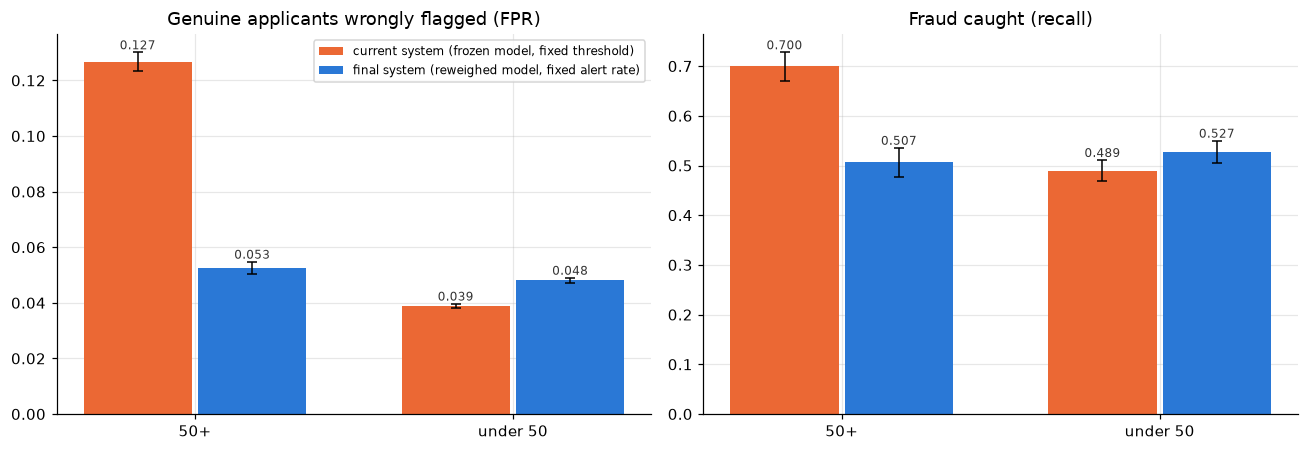

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (title, columns) in zip(axes, [('Genuine applicants wrongly flagged (FPR)', ['FPR 50+', 'FPR under 50']),
                                       ('Fraud caught (recall)', ['TPR 50+', 'TPR under 50'])]):
    x = np.arange(2)
    for k, (system, colour) in enumerate((('current', ORANGE), ('final', BLUE))):
        iv = pd.concat([with_interval(results_test, [system], c) for c in columns])
        ax.bar(x + (k - 0.5) * 0.36, iv['estimate'], width=0.34, color=colour, label=LABELS[system],
               yerr=[iv['estimate'] - iv['CI low'], iv['CI high'] - iv['estimate']], capsize=3, error_kw={'linewidth': 1})
        for xi, v, top in zip(x + (k - 0.5) * 0.36, iv['estimate'], iv['CI high']):
            ax.text(xi, top, f'{v:.3f}', ha='center', va='bottom', fontsize=8, color='#333333')
    ax.set_xticks(x, ['50+', 'under 50'])
    ax.set_title(title)
axes[0].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

**Findings**

- **The age gap is closed.** Predictive equality rises from **0.307 to 0.916** (+0.609, interval +0.571 to +0.646). Genuine 50+ applicants are wrongly flagged 5.3% of the time instead of 12.7%; genuine applicants under 50 4.8% instead of 3.9%. Per 1,000 applicants, the 50+ group gets **72 fewer false alarms** (122.9 to 51.0) and the others 9 more (38.5 to 47.6).
- **Recall is lower by 4.1 points** (0.562 to 0.520, interval -0.051 to -0.031). Section 7.2 shows that **1.7 points of this come from the alert rate, not from fairness**: on the test months the current system's fixed threshold flags more than its budget (FPR 5.3% instead of 5%, alert rate 6.0% instead of 5.6%), so part of its recall is bought with extra alerts.
- **The fraud caught moves between the groups.** Recall for 50+ falls from 0.700 to 0.507 and for under 50 rises from 0.489 to 0.527: equal opportunity goes from 0.699 to 0.961. The current system catches more fraud among older applicants *because* it flags many more of them; the final one treats both groups alike on both kinds of error.
- **Precision is unchanged** (0.131 to 0.132): each alert is as likely to be fraud as before.
- **Cost depends on R.** Per 10,000 applications the final system is cheaper at R = 5 (-13), slightly dearer at R = 10 (+16, interval +1 to +31, about 1.4%), and dearer at R = 20 (+74) and R = 50 (+248), because its cost is paid in missed fraud.
- **Month by month, the alert rate holds the FPR on target.** The final system flags 5.5% of applications in both months (FPR 5.0% and 4.8%); the current fixed threshold flags 6.6% in month 6 and 5.4% in month 7 (FPR 5.9% and 4.7%), so its workload moves by about 20% between two adjacent months. On month 7, where both flag about as many, recall is close (0.562 against 0.547). The fairness gain is the same in both months (predictive equality 0.926 and 0.907, against 0.315 and 0.308).

### **7.2 What Each Change Adds**
The two changes (reweighed model, fixed alert rate) one at a time. Differences are against the current system, paired.

In [14]:
COMPONENT_MEASURES = ['recall', 'FPR', 'alert rate', 'predictive equality', 'equal opportunity', f'cost per 10,000 (R={MAIN_RATIO})']
rows = []
for name in SYSTEMS:
    row = {'system': LABELS[name]}
    for column in COMPONENT_MEASURES:
        row[column] = results_test[name].loc[0, column]
    for column in ('recall', 'predictive equality', f'cost per 10,000 (R={MAIN_RATIO})'):
        d = paired_difference(results_test, name, 'current', column)
        digits = 0 if 'cost' in column else 3
        row[f'{column}: change'] = f"{d['difference']:+.{digits}f} ({d['CI low']:+.{digits}f} to {d['CI high']:+.{digits}f})"
    rows.append(row)
components = pd.DataFrame(rows).set_index('system')
components.round(4)

,recall,FPR,alert rate,predictive equality,equal opportunity,"cost per 10,000 (R=10)",recall: change,predictive equality: change,"cost per 10,000 (R=10): change"
system,,,,,,,,,
"current system (frozen model, fixed threshold)",0.5615,0.0531,0.0603,0.3072,0.6991,1139.441284,+0.000 (+0.000 to +0.000),+0.000 (+0.000 to +0.000),+0 (+0 to +0)
"frozen model, fixed alert rate",0.5448,0.0487,0.0557,0.3068,0.6983,1119.598511,-0.017 (-0.020 to -0.013),-0.000 (-0.003 to +0.002),-20 (-26 to -14)
"reweighed model, fixed threshold",0.5381,0.0532,0.0601,0.9027,0.9768,1173.429688,-0.023 (-0.033 to -0.014),+0.596 (+0.559 to +0.630),+34 (+19 to +49)
"final system (reweighed model, fixed alert rate)",0.5202,0.0488,0.0555,0.9161,0.9611,1155.157471,-0.041 (-0.051 to -0.031),+0.609 (+0.571 to +0.646),+16 (+1 to +31)


**Findings**

- **Fixed alert rate alone** (frozen model): recall -0.017, predictive equality unchanged (0.307), cost **-20** per 10,000 (interval -26 to -14). It changes how many are flagged, not who.
- **Reweighing alone** (fixed threshold): recall -0.023, predictive equality **+0.596**, cost +34 (+19 to +49), as notebook 06 found (+33 to +36).
- **Both** (the final system): recall -0.041, predictive equality +0.609, cost +16 (+1 to +31).
- **The price of fairness at equal workload** is the final system against "frozen model, fixed alert rate": recall 0.545 to 0.520 (-0.025) and cost 1,120 to 1,155 (+35, about 3%). The alert rate saves about as much as reweighing costs at R = 10.

### **7.3 One Seed against the Mean**
Every number above is the mean over 5 seeds; a bank would deploy one model (seed 0). The spread over seeds shows how far one copy can be from the mean (notebook 04, section 4, measures the same spread for the frozen model).

In [15]:
SEED_MEASURES = ['recall', 'predictive equality', f'cost per 10,000 (R={MAIN_RATIO})']
per_seed = pd.DataFrame([evaluate_flags(y_test, old_test, {'final': {s: flags_test['final'][s]}}, n_resamples=0)['final'].loc[0, SEED_MEASURES]
                         for s in SEEDS], index=SEEDS)
print('Final system over the 5 seeds: ' + '; '.join(f"{m} {per_seed[m].min():.{digits_of(m)}f}-{per_seed[m].max():.{digits_of(m)}f}" for m in SEED_MEASURES))
print(f'Seed {DEPLOYED_SEED} (the deployed copy): ' + '; '.join(f"{m} {per_seed.loc[DEPLOYED_SEED, m]:.{digits_of(m)}f}" for m in SEED_MEASURES))

Final system over the 5 seeds: recall 0.518-0.524; predictive equality 0.905-0.929; cost per 10,000 (R=10) 1150-1159
Seed 0 (the deployed copy): recall 0.524; predictive equality 0.919; cost per 10,000 (R=10) 1150


## **8. Robustness**
### **8.1 The BAF Variants**
The professor's protocol: the system is fitted and set up on Base only, then **scored unchanged** on the test months of each variant (nothing refitted; the alert rate is applied month by month). Notebook 06, section 9.3, asked a different question (retrain the recipe on each variant); this is the deployed system.

**What to look for.** Predictive equality of the final system on every variant, against the current system's, and whether recall holds up.

In [16]:
VARIANT_MEASURES = ['recall', 'FPR', 'precision', 'alert rate', 'predictive equality', 'equal opportunity', f'cost per 10,000 (R={MAIN_RATIO})']
rows = []
for dataset in DATASETS:
    part = scores[(scores['dataset'] == dataset) & scores['month'].isin(TEST_MONTHS)].reset_index(drop=True)
    flags = {n: system_flags(n, part) for n in ('current', 'final')}
    res = evaluate_flags(part['y_true'].to_numpy(), part['age_50_plus'].to_numpy(), flags)
    for n in ('current', 'final'):
        row = {'dataset': dataset, 'system': n, 'fraud rate': part['y_true'].mean()}
        for m in VARIANT_MEASURES:
            iv = with_interval(res, [n], m).iloc[0]
            row[m], row[f'{m} CI low'], row[f'{m} CI high'] = iv['estimate'], iv['CI low'], iv['CI high']
        rows.append(row)
variants = pd.DataFrame(rows).set_index(['dataset', 'system'])
variants[['fraud rate'] + VARIANT_MEASURES].round(4)

fraud rate  recall     FPR  precision  alert rate  \
dataset     system                                                       
base        current       0.014  0.5615  0.0531     0.1308      0.0603   
            final         0.014  0.5202  0.0488     0.1317      0.0555   
variant_i   current       0.014  0.5093  0.0491     0.1287      0.0555   
            final         0.014  0.5141  0.0489     0.1301      0.0555   
variant_ii  current       0.014  0.6605  0.0836     0.1011      0.0917   
            final         0.014  0.4912  0.0493     0.1243      0.0555   
variant_iii current       0.011  0.5842  0.0842     0.0715      0.0897   
            final         0.011  0.4978  0.0506     0.0985      0.0555   
variant_iv  current       0.011  0.5842  0.0842     0.0715      0.0897   
            final         0.011  0.4978  0.0506     0.0985      0.0555   
variant_v   current       0.011  0.5934  0.0832     0.0734      0.0888   
            final         0.011  0.5107  0.0504     0.1010      0.0555   

                     predictive equality  equal opportunity  \
dataset     system                                            
base        current               0.3072             0.6991   
            final                 0.9161             0.9611   
variant_i   current               0.3076             0.7123   
            final                 0.9006             0.8962   
variant_ii  current               0.3054             0.6465   
            final                 0.9004             0.9605   
variant_iii current               0.3058             0.6845   
            final                 0.8981             0.9698   
variant_iv  current               0.3058             0.6845   
            final                 0.8981             0.9698   
variant_v   current               0.3089             0.6684   
            final                 0.9051             0.9987   

                     cost per 10,000 (R=10)  
dataset     system                           
base        current               1139.4413  
            final                 1155.1575  
variant_i   current               1172.7721  
            final                 1164.6066  
variant_ii  current               1300.9219  
            final                 1199.9122  
variant_iii current               1289.0033  
            final                 1051.0775  
variant_iv  current               1289.0033  
            final                 1051.0775  
variant_v   current               1268.7362  
            final                 1035.5110

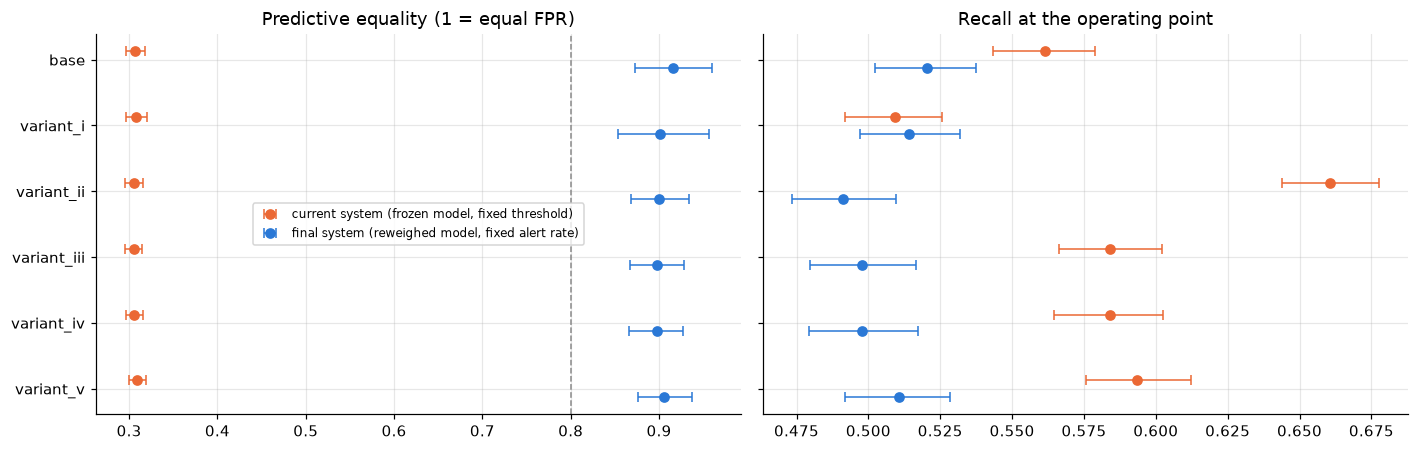

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
y_pos = np.arange(len(DATASETS))
for ax, measure, title in ((axes[0], 'predictive equality', 'Predictive equality (1 = equal FPR)'), (axes[1], 'recall', 'Recall at the operating point')):
    for k, (n, colour) in enumerate((('current', ORANGE), ('final', BLUE))):
        part = variants.xs(n, level='system').loc[DATASETS]
        ax.errorbar(part[measure], y_pos + (k - 0.5) * 0.25, xerr=[part[measure] - part[f'{measure} CI low'], part[f'{measure} CI high'] - part[measure]],
                    fmt='o', color=colour, markersize=6, capsize=3, linewidth=1, label=LABELS[n])
    ax.set_title(title)
axes[0].axvline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1)
axes[0].set_yticks(y_pos, DATASETS)
axes[0].invert_yaxis()
axes[0].legend(loc='center', fontsize=8)
plt.tight_layout()
plt.show()

**Findings**

- **The final system is fair on every dataset**: predictive equality 0.898-0.916 on Base and all five variants, against 0.305-0.309 for the current system. Nothing was refitted.
- **It also keeps its operating point.** Its FPR is 4.9-5.1% and its alert rate 5.55% everywhere; the current system's fixed threshold flags up to 9.2% of applications on Variants II-V (FPR 8.3-8.4%).
- **Recall is 0.49-0.52 on every dataset.** The current system's higher recall on Variants II-V (0.58-0.66) is bought with those extra alerts, and its precision is lower (0.07-0.10 against 0.10-0.12).
- **Cost (R = 10):** the final system is cheaper on Variants I-V (for example 1,051 against 1,289 on III and IV, 1,036 against 1,269 on V) and only dearer on Base (+16).
- Variants III and IV give identical numbers because their test months contain exactly the same applications (notebook 02, section 8).

### **8.2 Other Fraud Rates**
The professor's question: at a realistic fraud rate (for example 1% or lower), do the false positives spike? The fraud rate is changed by re-weighting the fraud and genuine test applications, with notebook 04's formulas (section 8). The difference from notebook 04 is the decision rule:
- **current**: the fixed threshold, so recall and FPR do not change with the fraud rate, only precision and the false alarms per fraud caught;
- **final**: a fixed alert rate, so the threshold moves with the fraud rate. With less fraud, the same share of alerts holds more genuine applicants and the FPR rises above 5%; with more fraud, the FPR falls and recall falls.

Mean over the 5 seeds.

In [18]:
PREVALENCES = [0.001, 0.005, 0.01, float(y_test.mean()), 0.02, 0.05]


def rates_at_fraud_rate(system, seed, pi):
    model, rule = SYSTEMS[system]
    s = test[f'{model}_seed{seed}'].to_numpy()
    genuine, fraud = y_test == 0, y_test == 1
    if rule == 'threshold':
        flagged = s >= cuts[model][seed]
    else:   # the score above which the alert rate of applications lies, with the classes weighted to fraud rate pi
        w = np.where(fraud, pi / fraud.sum(), (1 - pi) / genuine.sum())
        order = np.argsort(-s, kind='stable')
        k = min(np.searchsorted(np.cumsum(w[order]), alert_rates[model][seed]), len(s) - 1)
        flagged = s >= s[order][k]
    fpr_old, fpr_young = flagged[genuine & old_test].mean(), flagged[genuine & ~old_test].mean()
    tpr, fpr = flagged[fraud].mean(), flagged[genuine].mean()
    return {'recall': tpr, 'FPR': fpr, **at_fraud_rate(tpr, fpr, pi),
            'predictive equality': min(fpr_old, fpr_young) / max(fpr_old, fpr_young)}


rows = []
for pi in PREVALENCES:
    for n in ('current', 'final'):
        r = pd.DataFrame([rates_at_fraud_rate(n, seed, pi) for seed in SEEDS]).mean()
        rows.append({'fraud rate': pi, 'system': n, **r})
fraud_rates = pd.DataFrame(rows).set_index(['fraud rate', 'system'])
fraud_rates.round(4)

recall     FPR  precision  alerts per 10,000  \
fraud rate system                                                  
0.001000   current  0.5615  0.0531     0.0105           536.4071   
           final    0.5449  0.0550     0.0098           554.6857   
0.005000   current  0.5615  0.0531     0.0504           556.7419   
           final    0.5373  0.0530     0.0484           554.6762   
0.010000   current  0.5615  0.0531     0.0965           582.1603   
           final    0.5267  0.0507     0.0950           554.6699   
0.014038   current  0.5615  0.0531     0.1308           602.6896   
           final    0.5187  0.0489     0.1313           554.6629   
0.020000   current  0.5615  0.0531     0.1774           632.9972   
           final    0.5077  0.0462     0.1831           554.6739   
0.050000   current  0.5615  0.0531     0.3574           785.5078   
           final    0.4502  0.0347     0.4058           554.6986   

                    fraud caught per 10,000  false alarms per fraud caught  \
fraud rate system                                                            
0.001000   current                   5.6150                        94.5317   
           final                     5.4489                       100.7994   
0.005000   current                  28.0751                        18.8306   
           final                    26.8659                        19.6463   
0.010000   current                  56.1501                         9.3680   
           final                    52.6685                         9.5316   
0.014038   current                  78.8250                         6.6460   
           final                    72.8156                         6.6174   
0.020000   current                 112.3002                         4.6367   
           final                   101.5427                         4.4626   
0.050000   current                 280.7505                         1.7979   
           final                   225.0869                         1.4644   

                    predictive equality  
fraud rate system                        
0.001000   current               0.3072  
           final                 0.9011  
0.005000   current               0.3072  
           final                 0.9027  
0.010000   current               0.3072  
           final                 0.9032  
0.014038   current               0.3072  
           final                 0.9024  
0.020000   current               0.3072  
           final                 0.9056  
0.050000   current               0.3072  
           final                 0.9196

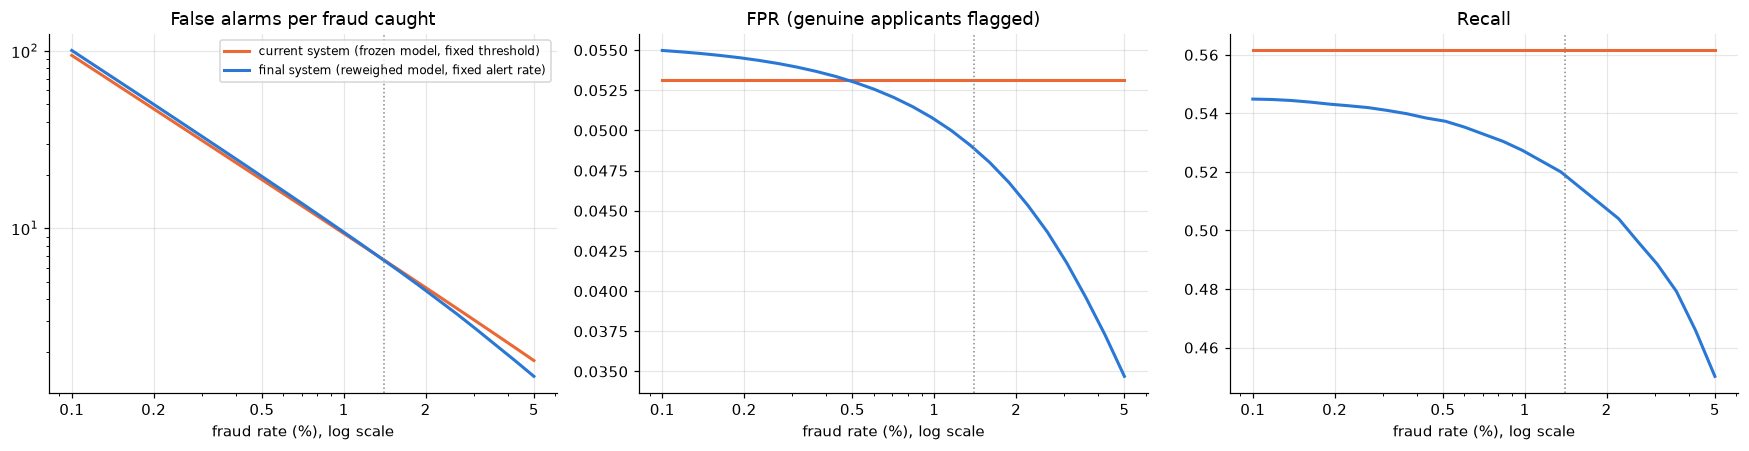

In [19]:
grid = np.logspace(np.log10(0.001), np.log10(0.05), 25)
curves = {n: pd.DataFrame([pd.DataFrame([rates_at_fraud_rate(n, s, pi) for s in SEEDS]).mean() for pi in grid], index=grid) for n in ('current', 'final')}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, measure, title in zip(axes, ['false alarms per fraud caught', 'FPR', 'recall'],
                              ['False alarms per fraud caught', 'FPR (genuine applicants flagged)', 'Recall']):
    for n, colour in (('current', ORANGE), ('final', BLUE)):
        ax.plot(grid * 100, curves[n][measure], color=colour, linewidth=2, label=LABELS[n])
    ax.axvline(y_test.mean() * 100, color=GREY, linestyle=':', linewidth=1)
    ax.set_xscale('log')
    ax.set_xticks([0.1, 0.2, 0.5, 1, 2, 5], ['0.1', '0.2', '0.5', '1', '2', '5'])
    ax.set_xlabel('fraud rate (%), log scale')
    ax.set_title(title)
axes[0].set_yscale('log')
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Findings**

**The professor's question: do false positives spike at a realistic fraud rate?**
- **The FPR does not spike.** The current system's FPR is 5.3% at any fraud rate (a fixed threshold). The final system's FPR moves with the fraud rate: 5.5% at 0.1%, 5.1% at 1%, 4.6% at 2%. At lower fraud the fixed number of alerts is filled with more genuine applicants.
- **The false alarms per fraud caught do spike, and that is the real-world problem.** At 1% fraud each fraud caught costs about **9.5 false alarms** (precision 9.5%) for both systems; at 0.5% about 19; at 0.1% about **95-100** (precision 1%). This is a property of rare events, not of the model: precision falls almost in proportion to the fraud rate.
- **The weak point of the alert rate is rising fraud.** At 5% fraud the final system's recall falls to 0.45 (the current system keeps 0.56), because it still flags only 5.55% of applications. That is why the alert rate must be re-set when the fraud share changes (section 12.2).
- **Fairness holds at every fraud rate**: the final system's predictive equality stays at 0.90-0.92 from 0.1% to 5%.

## **9. Stage 4: Human Review (FiFAR)**
FiFAR's 30,622 alerts are Base applications flagged by **Feedzai's own alert model**, each with the decision of 50 synthetic analysts (notebook 03). The review stage is tested on those alerts: our model scores them, the least-sure share goes to analysts, and the model decides the rest with the lowest-cost threshold of notebook 03 (picked on the history months 4-6, at each cost ratio). Month 7 (4,457 alerts, 711 fraud) is the test.

**A limit to keep in mind.** The alerts were chosen by Feedzai's model, not by ours, so this tests the review stage *given a set of alerts*. Section 11 measures how much our alerts and FiFAR's overlap.

| Policy | Alerts reviewed | Analysts |
|---|---|---|
| AI only | none | - |
| Unsure alerts, best 10 by cost | the least sure 50% (notebook 03's rule) | the 10 with the lowest history cost (notebook 03's policy: the current system) |
| Unsure alerts, all 50 analysts | as above | any of the 50 (notebook 06, section 10, found this about as fair as the fair pool) |
| **Unsure alerts, best 10 with PE >= 0.8** | as above | the 10 with the lowest history cost among those with history predictive equality at least 0.8 (the **final system**) |

In [20]:
fa_alerts = pd.read_parquet(f'{FIFAR_DIR}/alert_data/processed_data/alerts.parquet')
expert_predictions = pd.read_parquet(f'{FIFAR_DIR}/synthetic_experts/expert_predictions.parquet')
ANALYSTS = list(expert_predictions.columns)
expert_predictions = expert_predictions.loc[fa_alerts.index]

# Link each alert to its Base row (notebook 03, section 3.1)
KEY = ['name_email_similarity', 'velocity_6h', 'credit_risk_score', 'customer_age', 'month']
left = fa_alerts[KEY].round(6).reset_index()
right = base_raw[KEY].round(6).reset_index(names='row_id')
link = left.merge(right, on=KEY, how='left').set_index('case_id')
print(f"{link['row_id'].notna().sum():,} of {len(fa_alerts):,} alerts matched to a Base row, {link.index.duplicated().sum()} matched twice")
fa_alerts['row_id'] = link.loc[fa_alerts.index, 'row_id'].astype(int)

# Months 4-7 only (our scores cover them; month 3 was training data, as in notebook 03)
keep = fa_alerts['month'].isin(FA_HISTORY_MONTHS + FA_TEST_MONTHS).to_numpy()
fa_alerts, expert_predictions = fa_alerts[keep], expert_predictions[keep]
by_row = base_scores.set_index('row_id')
assert (by_row.loc[fa_alerts['row_id'], 'customer_age'].to_numpy() == fa_alerts['customer_age'].to_numpy()).all(), 'the linked rows do not match'
for name in MODELS:
    for seed in SEEDS:
        fa_alerts[f'{name}_seed{seed}'] = by_row.loc[fa_alerts['row_id'], f'{name}_seed{seed}'].to_numpy()

fa_hist = fa_alerts['month'].isin(FA_HISTORY_MONTHS).to_numpy()
fa_test = fa_alerts['month'].isin(FA_TEST_MONTHS).to_numpy()
fa_y_hist, fa_y_test = fa_alerts.loc[fa_hist, TARGET].to_numpy(), fa_alerts.loc[fa_test, TARGET].to_numpy()
fa_old_hist = (fa_alerts.loc[fa_hist, 'customer_age'] >= AGE_CUT).to_numpy()
fa_old_test = (fa_alerts.loc[fa_test, 'customer_age'] >= AGE_CUT).to_numpy()
D_hist = expert_predictions.to_numpy()[fa_hist].astype(bool)      # alerts x analysts
D_test = expert_predictions.to_numpy()[fa_test].astype(bool)
print(f'{len(ANALYSTS)} analysts; history alerts (months {FA_HISTORY_MONTHS}): {fa_hist.sum():,} ({fa_y_hist.sum():,} fraud); '
      f'test alerts (month {FA_TEST_MONTHS}): {fa_test.sum():,} ({fa_y_test.sum():,} fraud)')

30,622 of 30,622 alerts matched to a Base row, 0 matched twice
50 analysts; history alerts (months [4, 5, 6]): 17,883 (2,197 fraud); test alerts (month [7]): 4,457 (711 fraud)


### **9.1 The Analyst Pools**
Chosen on the history months only, as in notebook 06, section 10.2.

In [21]:
fa_thresholds = {(name, ratio, seed): lowest_cost_threshold(fa_y_hist, fa_alerts.loc[fa_hist, f'{name}_seed{seed}'].to_numpy(), ratio)
                 for name in MODELS for ratio in COST_RATIOS for seed in SEEDS}
analyst_profile = pd.DataFrame(group_measures(D_hist, fa_y_hist, fa_old_hist), index=ANALYSTS)
history_cost = {ratio: np.array([ratio * ((fa_y_hist == 1) & ~D_hist[:, j]).sum() + ((fa_y_hist == 0) & D_hist[:, j]).sum()
                                 for j in range(len(ANALYSTS))]) for ratio in COST_RATIOS}
pools = {}
for ratio in COST_RATIOS:
    order = np.argsort(history_cost[ratio])
    pools[('all', ratio)] = np.arange(len(ANALYSTS))
    pools[('best', ratio)] = order[:POOL_SIZE]
    pools[('fair', ratio)] = order[analyst_profile['predictive equality'].to_numpy()[order] >= POOL_MIN_PE][:POOL_SIZE]

POOL_NAMES = {'all': 'all 50 analysts', 'best': 'best 10 by cost (notebook 03)', 'fair': f'best 10 with PE >= {POOL_MIN_PE} (final)'}
rows = []
for pool, label in POOL_NAMES.items():
    members = pools[(pool, MAIN_RATIO)]
    rows.append({'pool': label, 'analysts': len(members), 'mean history PE': analyst_profile['predictive equality'].to_numpy()[members].mean(),
                 'mean history cost per 1,000 alerts (R=10)': 1000 * history_cost[MAIN_RATIO][members].mean() / len(fa_y_hist)})
display(pd.DataFrame(rows).set_index('pool').round(3))
print(f'Final pool (R = {MAIN_RATIO}):', [ANALYSTS[j] for j in pools[('fair', MAIN_RATIO)]])
print(f'Notebook 03 pool (R = {MAIN_RATIO}):', [ANALYSTS[j] for j in pools[('best', MAIN_RATIO)]])

,analysts,mean history PE,"mean history cost per 1,000 alerts (R=10)"
pool,,,
all 50 analysts,50,0.792,466.752
best 10 by cost (notebook 03),10,0.692,350.294
best 10 with PE >= 0.8 (final),10,0.850,446.950


Final pool (R = 10): ['standard#28', 'standard#43', 'standard#41', 'standard#49', 'standard#46', 'standard#18', 'standard#5', 'standard#2', 'standard#45', 'standard#14']
Notebook 03 pool (R = 10): ['standard#38', 'standard#48', 'standard#10', 'standard#39', 'standard#37', 'standard#40', 'standard#7', 'standard#21', 'standard#17', 'standard#12']


### **9.2 The Simulation**
Copied from notebook 06, section 10.2 (which extends notebook 03, section 6.2), with the model as an argument. Each alert sent to review goes to an analyst drawn at random from the pool; 5 runs, run *s* uses seed *s* for the model and for the draw.

**Check.** With the frozen model, the simulation must reproduce notebook 06, section 10.3, at half capacity and R = 10: AI only 796 per 1,000 alerts (PE 0.754), notebook 03's policy 510 (0.727), the fair pool 596 (0.804), all 50 analysts 583 (0.802). The two notebooks score the alerts in separate runs, so a score sitting exactly on a threshold can fall either side; the check allows 1 in cost and 0.002 in predictive equality.

In [22]:
POLICY_POOLS = {'AI only': None, 'Unsure alerts, best 10 by cost': 'best',
                'Unsure alerts, all 50 analysts': 'all', 'Unsure alerts, best 10 with PE >= 0.8': 'fair'}
CURRENT_POLICY, FINAL_POLICY = 'Unsure alerts, best 10 by cost', 'Unsure alerts, best 10 with PE >= 0.8'
CAPACITIES = np.round(np.arange(0, 1.01, 0.1), 1)
fa_test_scores = {name: {seed: fa_alerts.loc[fa_test, f'{name}_seed{seed}'].to_numpy() for seed in SEEDS} for name in MODELS}


def fa_simulate(model, policy, capacity, ratio, seed):
    # Copied from notebook 06, section 10.2 ("unsure" routing), with the model as an argument.
    rng = np.random.default_rng(seed)
    scores_ = fa_test_scores[model][seed]
    threshold = fa_thresholds[(model, ratio, seed)]
    decisions = scores_ >= threshold
    reviewed = np.array([], dtype=int)
    pool = POLICY_POOLS[policy]
    if pool is not None and capacity > 0:
        distance = np.abs(logit(scores_) - logit(min(threshold, 1)))
        reviewed = np.argsort(distance)[:int(round(capacity * len(scores_)))]
        assigned = rng.choice(pools[(pool, ratio)], size=len(reviewed))
        decisions[reviewed] = D_test[reviewed, assigned]
    return decisions, reviewed


def fa_metrics(decisions, reviewed, ratio):
    # Copied from notebook 06, section 10.2.
    m = {k: v[0] for k, v in group_measures(decisions, fa_y_test, fa_old_test).items()}
    n = len(decisions)
    m['cost per 1,000 alerts'] = 1000 * (ratio * ((fa_y_test == 1) & ~decisions).sum() + ((fa_y_test == 0) & decisions).sum()) / n
    in_review = np.zeros(n, dtype=bool)
    in_review[reviewed] = True
    m['review rate 50+'], m['review rate under 50'] = in_review[fa_old_test].mean(), in_review[~fa_old_test].mean()
    return m


rows = []
for model in MODELS:
    for ratio in COST_RATIOS:
        for policy in POLICY_POOLS:
            for capacity in CAPACITIES:
                for seed in SEEDS:
                    decisions, reviewed = fa_simulate(model, policy, capacity, ratio, seed)
                    rows.append({'model': model, 'cost ratio': ratio, 'policy': policy, 'capacity': capacity, 'seed': seed,
                                 **fa_metrics(decisions, reviewed, ratio)})
fa_simulation = pd.DataFrame(rows)

notebook_06 = {'AI only': (796, 0.754), CURRENT_POLICY: (510, 0.727), FINAL_POLICY: (596, 0.804), 'Unsure alerts, all 50 analysts': (583, 0.802)}
at = fa_simulation[(fa_simulation['model'] == 'frozen') & (fa_simulation['cost ratio'] == MAIN_RATIO) & (fa_simulation['capacity'] == REVIEW_CAPACITY)]
check = at.groupby('policy')[['cost per 1,000 alerts', 'predictive equality']].mean()
for policy, (cost, pe) in notebook_06.items():
    print(f'{policy:40s} cost {check.loc[policy, "cost per 1,000 alerts"]:6.1f} (notebook 06: {cost}), '
          f'PE {check.loc[policy, "predictive equality"]:.3f} (notebook 06: {pe})')
    assert abs(check.loc[policy, 'cost per 1,000 alerts'] - cost) < 1 and abs(check.loc[policy, 'predictive equality'] - pe) < 0.002

AI only                                  cost  796.1 (notebook 06: 796), PE 0.754 (notebook 06: 0.754)
Unsure alerts, best 10 by cost           cost  509.6 (notebook 06: 510), PE 0.726 (notebook 06: 0.727)
Unsure alerts, best 10 with PE >= 0.8    cost  595.8 (notebook 06: 596), PE 0.804 (notebook 06: 0.804)
Unsure alerts, all 50 analysts           cost  583.3 (notebook 06: 583), PE 0.802 (notebook 06: 0.802)


### **9.3 Results at Half Capacity (R = 10)**
The **current system** (frozen model, notebook 03's policy) against the final model under every policy. The frozen model's other policies are in notebook 06, section 10.3, and reproduced by the check above. Mean over the 5 runs; the last two columns are the change from the current system, with the spread over runs.

In [23]:
REVIEW_MEASURES = ['cost per 1,000 alerts', 'recall', 'FPR', 'FPR 50+', 'FPR under 50', 'recall 50+', 'recall under 50',
                   'predictive equality', 'equal opportunity', 'equalised odds difference']
at = fa_simulation[(fa_simulation['cost ratio'] == MAIN_RATIO) & (fa_simulation['capacity'] == REVIEW_CAPACITY)]
current_runs = at[(at['model'] == 'frozen') & (at['policy'] == CURRENT_POLICY)].set_index('seed')
REVIEW_ROWS = [('frozen', CURRENT_POLICY)] + [('reweighed', p) for p in POLICY_POOLS]
rows = []
for model, policy in REVIEW_ROWS:
    runs = at[(at['model'] == model) & (at['policy'] == policy)].set_index('seed')
    row = {'system': 'current system' if (model, policy) == ('frozen', CURRENT_POLICY) else f'final model, {policy}', **runs[REVIEW_MEASURES].mean()}
    for column in ('cost per 1,000 alerts', 'predictive equality'):
        d = runs[column] - current_runs[column]
        row[f'{column}: change (sd)'] = f'{d.mean():+.3f} ({d.std():.3f})'
    rows.append(row)
review = pd.DataFrame(rows).set_index('system')
review.round(3)

,"cost per 1,000 alerts",recall,FPR,FPR 50+,FPR under 50,recall 50+,recall under 50,predictive equality,equal opportunity,equalised odds difference,"cost per 1,000 alerts: change (sd)",predictive equality: change (sd)
system,,,,,,,,,,,,
current system,509.580,0.840,0.302,0.373,0.271,0.885,0.811,0.726,0.917,0.102,+0.000 (0.000),+0.000 (0.000)
"final model, AI only",798.519,0.800,0.570,0.326,0.677,0.664,0.884,0.478,0.750,0.351,+288.939 (32.435),-0.249 (0.063)
"final model, Unsure alerts, best 10 by cost",528.337,0.873,0.388,0.284,0.434,0.843,0.892,0.655,0.946,0.150,+18.757 (22.823),-0.071 (0.015)
"final model, Unsure alerts, all 50 analysts",605.071,0.883,0.498,0.408,0.538,0.848,0.905,0.757,0.936,0.130,+95.490 (13.526),+0.031 (0.041)
"final model, Unsure alerts, best 10 with PE >= 0.8",620.552,0.908,0.563,0.477,0.601,0.865,0.934,0.792,0.926,0.124,+110.972 (15.209),+0.065 (0.047)


**Findings**

- **The check reproduces notebook 06, section 10.3** for the frozen model (796 / 510 / 596 / 583 per 1,000 alerts, predictive equality to within 0.001).
- **The final system's review stage** (final model, fair pool) costs **621 per 1,000 alerts** against **510** for the current system (+111, sd 15, +22%), catches more fraud (recall 0.908 against 0.840) and is fairer (predictive equality 0.792 against 0.726, +0.065 with sd 0.047 over runs, so not clearly beyond the simulation noise). It is just under the 0.8 reference at half capacity.
- **The gap changes direction on the alerts.** With the final model alone (AI only), genuine *under-50* alerts are flagged more (FPR 0.677 against 0.326 for 50+, predictive equality 0.478). These alerts were chosen by Feedzai's model, and the final model no longer scores older applicants up (section 10). The analysts lean the other way (they flag genuine 50+ applicants more, notebook 06, section 10.1), so sending the unsure half to analysts brings the two groups closer together again.
- **With the final model the fair pool matters more.** Notebook 03's cheapest analysts give only 0.655 with it, against 0.792 for the fair pool and 0.757 for all 50.
- **Where the extra cost comes from.** AI only costs about the same with either model (799 against 796, check above). The fair pool itself adds 86 with the frozen model (596 against 510, check above), and its combination with the final model about 25 more (621 against 596).

### **9.4 Capacity and Cost Ratio**
With the final model: cost and predictive equality for every share of alerts reviewed (R = 10), the smallest capacity that reaches 0.8, and the half-capacity results at the other cost ratios.

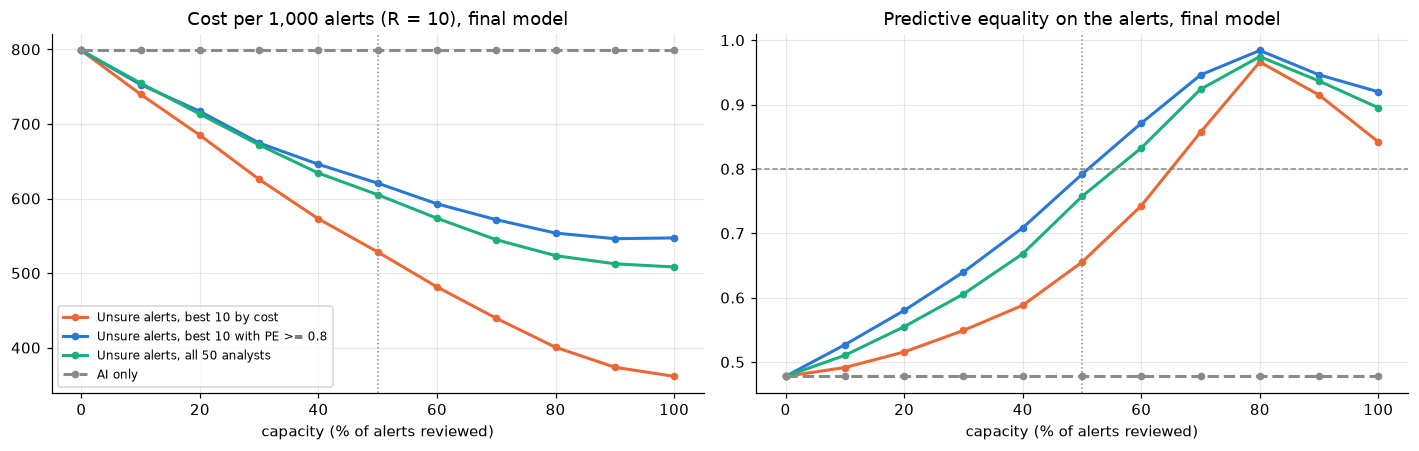

AI only                                  reaches predictive equality 0.8 at capacity: never
Unsure alerts, best 10 by cost           reaches predictive equality 0.8 at capacity: 70%
Unsure alerts, all 50 analysts           reaches predictive equality 0.8 at capacity: 60%
Unsure alerts, best 10 with PE >= 0.8    reaches predictive equality 0.8 at capacity: 60%
R =  5, half capacity: fair pool cost 498, PE 0.552; notebook 03's pool cost 368, PE 0.789
R = 10, half capacity: fair pool cost 621, PE 0.792; notebook 03's pool cost 528, PE 0.655
R = 20, half capacity: fair pool cost 679, PE 0.893; notebook 03's pool cost 652, PE 0.793
R = 50, half capacity: fair pool cost 713, PE 0.911; notebook 03's pool cost 751, PE 0.913


In [24]:
final_rows = fa_simulation[(fa_simulation['model'] == 'reweighed') & (fa_simulation['cost ratio'] == MAIN_RATIO)]
curve = final_rows.groupby(['policy', 'capacity'], sort=False)[['cost per 1,000 alerts', 'predictive equality']].mean()
styles = {CURRENT_POLICY: dict(color=ORANGE), FINAL_POLICY: dict(color=BLUE),
          'Unsure alerts, all 50 analysts': dict(color=GREEN), 'AI only': dict(color=GREY, linestyle='--')}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for policy, style in styles.items():
    part = curve.loc[policy]
    axes[0].plot(part.index * 100, part['cost per 1,000 alerts'], linewidth=2, marker='o', markersize=4, label=policy, **style)
    axes[1].plot(part.index * 100, part['predictive equality'], linewidth=2, marker='o', markersize=4, label=policy, **style)
axes[0].set_title('Cost per 1,000 alerts (R = 10), final model')
axes[1].set_title('Predictive equality on the alerts, final model')
for ax in axes:
    ax.set_xlabel('capacity (% of alerts reviewed)')
    ax.axvline(REVIEW_CAPACITY * 100, color=GREY, linestyle=':', linewidth=1)
axes[1].axhline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

for policy in POLICY_POOLS:
    part = curve.loc[policy]['predictive equality']
    reached = part[part >= FOUR_FIFTHS]
    print(f"{policy:40s} reaches predictive equality 0.8 at capacity: {f'{reached.index.min():.0%}' if len(reached) else 'never'}")
half = fa_simulation[(fa_simulation['model'] == 'reweighed') & (fa_simulation['capacity'] == REVIEW_CAPACITY)]
half = half.groupby(['cost ratio', 'policy'])[['cost per 1,000 alerts', 'predictive equality']].mean()
for ratio in COST_RATIOS:
    print(f'R = {ratio:2d}, half capacity: ' + '; '.join(
        f"{label} cost {half.loc[(ratio, policy), 'cost per 1,000 alerts']:.0f}, PE {half.loc[(ratio, policy), 'predictive equality']:.3f}"
        for label, policy in (('fair pool', FINAL_POLICY), ("notebook 03's pool", CURRENT_POLICY))))

**Findings**

- **Capacity needed to reach 0.8** (final model, R = 10): 60% of alerts for the fair pool and for all 50 analysts, 70% for notebook 03's pool; AI only never does.
- **Cost falls steadily with capacity** for every review policy, so more review is both cheaper and fairer up to about 80% (plot).
- **The cost ratio matters.** At R = 5 the fair pool is *less* fair than notebook 03's pool with the final model (0.552 against 0.789); at R = 20 it is fairer (0.893 against 0.793), and at R = 50 about as fair (0.911 against 0.913) and cheaper (713 against 751). So the choice of pool depends on R and should be re-checked if the bank's cost ratio is not about 10.

## **10. Does Notebook 05's Picture Still Hold?**
Notebook 05 explained the frozen model. The final model is retrained with different weights, so its explanations could differ. Two checks, with TreeSHAP contributions (XGBoost's `pred_contribs`, as in notebook 05) on the Base test months, all 5 seeds, in calibrated log-odds (each seed's contributions times its Platt slope):
- **Importance:** mean |contribution| of each feature group (a value and its `_missing` flag added together per application, notebook 05, section 4.1), as a share of the total. Does the final model rank the groups the same way?
- **Age:** among genuine applicants, the difference in mean contribution between 50+ and under 50, and the part carried by `customer_age` (the measure of notebook 06, section 4.3). Reweighing should shrink the part that age carries.

**Check.** For the frozen model, the age part must reproduce notebook 06, section 4.3: a total difference of 0.941 and 48% carried by `customer_age`.

In [25]:
X_test = make_features(base_raw.loc[test['row_id']], **FEATURES)
group_of = [c[:-len('_missing')] if c.endswith('_missing') else c for c in X_test.columns]
GROUP_NAMES = list(dict.fromkeys(group_of))
G = np.zeros((len(group_of), len(GROUP_NAMES)), dtype=np.float32)
for j, g in enumerate(group_of):
    G[j, GROUP_NAMES.index(g)] = 1
genuine_old, genuine_young = (y_test == 0) & old_test, (y_test == 0) & ~old_test
slopes = {'frozen': {s: frozen_calibration['seeds'][str(s)]['a'] for s in SEEDS}, 'reweighed': {s: platt[s].coef_[0, 0] for s in SEEDS}}

importance, age_gap = {}, {}
dmatrix = xgb.DMatrix(X_test, enable_categorical=True)
for name, models in MODELS.items():
    imp, gap = [], []
    for seed in SEEDS:
        grouped = (models[seed].get_booster().predict(dmatrix, pred_contribs=True)[:, :-1] @ G) * slopes[name][seed]   # drop the bias column
        imp.append(np.abs(grouped).mean(axis=0))
        gap.append(grouped[genuine_old].mean(axis=0) - grouped[genuine_young].mean(axis=0))
    importance[name] = pd.Series(np.mean(imp, axis=0), index=GROUP_NAMES)
    age_gap[name] = pd.Series(np.mean(gap, axis=0), index=GROUP_NAMES)

share = pd.DataFrame({name: importance[name] / importance[name].sum() for name in MODELS})
rank = share.rank(ascending=False).astype(int)
rho = np.corrcoef(rank['frozen'], rank['reweighed'])[0, 1]
top = share.sort_values('frozen', ascending=False).head(12)
importance_table = pd.DataFrame({'share, frozen': top['frozen'], 'rank, frozen': rank.loc[top.index, 'frozen'],
                                 'share, final': top['reweighed'], 'rank, final': rank.loc[top.index, 'reweighed']})
print(f'Rank correlation of the {len(GROUP_NAMES)} feature groups, frozen against final model: {rho:.3f}')
display(importance_table.round(3))

age_table = pd.DataFrame({name: {'total difference, 50+ minus under 50': age_gap[name].sum(),
                                 'carried by customer_age': age_gap[name]['customer_age'],
                                 'carried by the other feature groups': age_gap[name].drop('customer_age').sum()} for name in MODELS})
age_table.columns = ['frozen', 'final']
print(f"Check against notebook 06, section 4.3 (frozen model): total {age_gap['frozen'].sum():.3f} (0.941), "
      f"customer_age share {age_gap['frozen']['customer_age'] / age_gap['frozen'].sum():.0%} (48%)")
print('Mean contribution among genuine applicants, 50+ minus under 50 (calibrated log-odds, mean over 5 seeds):')
age_table.round(3)

Rank correlation of the 28 feature groups, frozen against final model: 0.995


,"share, frozen","rank, frozen","share, final","rank, final"
device_os,0.098,1,0.099,1
housing_status,0.083,2,0.080,2
phone_home_valid,0.077,3,0.079,3
prev_address_months_count,0.072,4,0.074,4
has_other_cards,0.062,5,0.063,5
name_email_similarity,0.058,6,0.060,6
current_address_months_count,0.057,7,0.057,8
keep_alive_session,0.057,8,0.057,7
email_is_free,0.051,9,0.051,9
income,0.049,10,0.048,10


Check against notebook 06, section 4.3 (frozen model): total 0.941 (0.941), customer_age share 48% (48%)
Mean contribution among genuine applicants, 50+ minus under 50 (calibrated log-odds, mean over 5 seeds):


,frozen,final
"total difference, 50+ minus under 50",0.941,-0.005
carried by customer_age,0.454,-0.464
carried by the other feature groups,0.487,0.459


**Findings**

- **The final model relies on the same features.** The 28 feature groups are ranked almost identically (rank correlation 0.995): `device_os`, `housing_status`, `phone_home_valid`, `prev_address_months_count` and `has_other_cards` are the top five in both models, with nearly the same shares (for example `device_os` 9.8% and 9.9%). Notebook 05's explanations, reason codes and sanity checks therefore describe the final model too.
- **The check reproduces notebook 06, section 4.3** for the frozen model: genuine 50+ applicants score 0.941 higher than genuine under-50 applicants (calibrated log-odds), and `customer_age` carries 48% of that.
- **Reweighing does not stop the model from using age; it turns age around.** In the final model the total difference is -0.005, essentially zero, which is why the two groups now have almost the same FPR (section 7.1). The proxies still push 50+ applicants up (+0.459), as in the frozen model (+0.487), but `customer_age` now pushes them down by about as much (-0.464, against +0.454 in the frozen model). Its overall importance hardly changes (rank 12 to 13, share 3.3% to 3.0%); only its direction for older applicants does.
- **What this means.** The model needs `customer_age` as an input to offset the proxies. A reweighed model without `customer_age` could not do this, which fits notebook 06, section 7.5: reweighing with age dropped reached predictive equality 0.86, against 0.90 with age kept (the intervals overlap, so this is a hint, not proof). It also means the final model treats age explicitly as a correction, which a reason code would show ("age pushes towards genuine"), so the bank's owners must be comfortable with that (section 12.1, fairness choice).

## **11. Known Limits**
Three things the final system does not fix, in one table:
- **Other groups:** predictive equality of each second-tier group (in the group against everyone else), on the Base test months. Notebook 06 found housing status BA the largest gap (0.08 for the frozen model) and that no age mitigation repairs it.
- **Probabilities by age group:** reweighing tells the model both age groups have the same fraud rate, so its probabilities should be too low for the 50+ group and too high for the others (observed / expected = 1 is well calibrated).
- **The review stage's alerts:** on Base month 7, how many of each system's alerts are also FiFAR alerts, the only alerts with analyst decisions.

In [26]:
rows = {}
for label, column in {name: name for name in SECOND_TIER}.items():
    res = evaluate_flags(y_test, test[column].to_numpy(), {n: flags_test[n] for n in ('current', 'final')})
    rows[f'predictive equality, {label}'] = {n: fmt(*with_interval(res, [n], 'predictive equality').iloc[0], digits=3) for n in ('current', 'final')}

probabilities = {'current': np.mean([calibrate(test[f'frozen_seed{s}'], s) for s in SEEDS], axis=0),
                 'final': np.mean([final_probability(test[f'reweighed_seed{s}'], s) for s in SEEDS], axis=0)}
for group, mask in (('50+', old_test), ('under 50', ~old_test)):
    rows[f'observed / expected fraud, {group}'] = {n: f'{y_test[mask].mean() / probabilities[n][mask].mean():.2f}' for n in ('current', 'final')}

month7 = test[test['month'] == 7]
fifar7 = set(fa_alerts.loc[fa_test, 'row_id'])
in_fifar = month7['row_id'].isin(fifar7).to_numpy()
overlap = {n: pd.DataFrame([{'ours in FiFAR': in_fifar[f].mean(), 'FiFAR we flag': f[in_fifar].mean()} for f in system_flags(n, month7).values()]).mean()
           for n in ('current', 'final')}
rows['share of our month-7 alerts that are FiFAR alerts'] = {n: f"{overlap[n]['ours in FiFAR']:.0%}" for n in ('current', 'final')}
rows['share of FiFAR month-7 alerts we flag'] = {n: f"{overlap[n]['FiFAR we flag']:.0%}" for n in ('current', 'final')}
known_limits = pd.DataFrame(rows).T
known_limits

,current,final
"predictive equality, income = 0.9",0.335 (0.323 to 0.347),0.324 (0.314 to 0.336)
"predictive equality, employment_status = CC",0.404 (0.377 to 0.435),0.864 (0.779 to 0.962)
"predictive equality, housing_status = BA",0.083 (0.079 to 0.086),0.085 (0.082 to 0.089)
"observed / expected fraud, 50+",1.08,2.13
"observed / expected fraud, under 50",1.14,0.91
share of our month-7 alerts that are FiFAR alerts,69%,63%
share of FiFAR month-7 alerts we flag,81%,76%


**Findings**

- **Housing status BA is still the largest gap and is untouched**: predictive equality 0.083 to 0.085. Notebook 06, section 9.4, showed that repairing it costs about 14 points of recall.
- **Employment status CC is repaired as a side effect** (0.404 to 0.864), because its gap is mostly an age effect (notebook 05, section 13). **Income 0.9 is unchanged** (0.335 to 0.324).
- **The final system's probabilities are wrong within age groups, as expected.** Observed / expected is 2.13 for the 50+ group and 0.91 for the others (current system: 1.08 and 1.14). For an older applicant the real chance of fraud is about twice what the final model shows, so its probabilities must not be shown to reviewers as an individual's risk. The flags are not affected (they come from the ranking and the alert rate); the current system's calibrator can be used for display.
- **The review stage mostly sees our own alerts, but not all of them.** 63% of the final system's month-7 alerts are also FiFAR alerts, and it flags 76% of FiFAR's alerts. About a third of its alerts have no analyst decisions in FiFAR, and section 9 cannot say how analysts would handle those.

## **12. Model Card and Monitoring**
Notebook 06 set up the accountability framework (a per-case decision log, owners, how to contest a decision, section 11) and left the model card and the monitor to this notebook.

### **12.1 Model Card**
The numbers are filled in from the results above (test months 6-7, mean over 5 seeds, 95% intervals); the text items are below the table.

In [27]:
def cell(results, name, column, digits=3):
    iv = with_interval(results, [name], column).iloc[0]
    return fmt(iv['estimate'], iv['CI low'], iv['CI high'], digits)


card_rows = {}
for n in ('current', 'final'):
    v = variants.xs(n, level='system')
    r = review.loc['current system' if n == 'current' else f'final model, {FINAL_POLICY}']
    card_rows[f'{n} system'] = {
        'recall (Base test months)': cell(results_test, n, 'recall'),
        'FPR / alert rate': f"{results_test[n].loc[0, 'FPR']:.3f} / {results_test[n].loc[0, 'alert rate']:.3f}",
        'precision': cell(results_test, n, 'precision'),
        'FPR 50+ / under 50': f"{results_test[n].loc[0, 'FPR 50+']:.3f} / {results_test[n].loc[0, 'FPR under 50']:.3f}",
        'predictive equality (50+ vs under 50)': cell(results_test, n, 'predictive equality'),
        'equal opportunity': cell(results_test, n, 'equal opportunity'),
        'cost per 10,000 applications (R = 10)': cell(results_test, n, f'cost per 10,000 (R={MAIN_RATIO})', 0),
        'predictive equality on the 6 BAF datasets': f"{v['predictive equality'].min():.2f}-{v['predictive equality'].max():.2f}",
        'recall on the 6 BAF datasets': f"{v['recall'].min():.2f}-{v['recall'].max():.2f}",
        'review stage (FiFAR month 7, half capacity): cost per 1,000 alerts / PE': f"{r['cost per 1,000 alerts']:.0f} / {r['predictive equality']:.3f}",
    }
pd.DataFrame(card_rows)

,current system,final system
recall (Base test months),0.562 (0.544 to 0.579),0.520 (0.502 to 0.537)
FPR / alert rate,0.053 / 0.060,0.049 / 0.055
precision,0.131 (0.125 to 0.136),0.132 (0.126 to 0.138)
FPR 50+ / under 50,0.127 / 0.039,0.053 / 0.048
predictive equality (50+ vs under 50),0.307 (0.296 to 0.318),0.916 (0.872 to 0.959)
equal opportunity,0.699 (0.661 to 0.744),0.961 (0.894 to 0.997)
"cost per 10,000 applications (R = 10)",1139 (1107 to 1177),1155 (1121 to 1194)
predictive equality on the 6 BAF datasets,0.31-0.31,0.90-0.92
recall on the 6 BAF datasets,0.51-0.66,0.49-0.52
"review stage (FiFAR month 7, half capacity): cost per 1,000 alerts / PE",510 / 0.726,621 / 0.792


| Item | Content |
|---|---|
| **Intended use** | Score new bank-account applications for fraud risk and decide which to flag for review. A flag means "check this application", never an automatic permanent rejection. Flagged applications the model is least sure about go to a human analyst (stage 4). |
| **Not intended for** | Credit decisions, pricing or any decision about creditworthiness; populations unlike BAF's (BAF is synthetic, generated from one bank's data); automatic closure of accounts. |
| **System** | Stage 1: notebook 02's XGBoost recipe (`configs/final_model.json`), retrained on Base months 0-3 with reweighing (section 4). Stage 2: a Platt calibrator per seed, fitted on month 5 (section 5). Stage 3: a fixed alert rate set on month 5 (section 6). Stage 4: the fair analyst pool at 50% capacity (section 9). Seed 0 is the deployed copy; results are the mean of seeds 0-4. |
| **Training data** | BAF Base months 0-3, reweighed so that age group (50+ vs under 50) and fraud are independent. `customer_age` is an input. |
| **Operating point** | A fixed alert rate set on month 5 (the share flagged by a 5%-FPR threshold). The review workload is fixed; the FPR moves with the fraud rate (section 8.2). |
| **Fairness choice** | Reweighing neutralises the higher fraud rate of older applicants in training. That is a value judgement, not a technical fact: it trades about 2 points of recall for near-equal false-alarm rates by age. It must be approved by the owners named in notebook 06, section 11.3. |
| **Known limits** | Section 11: housing status BA keeps a large gap; the probabilities are not calibrated within age groups; the review stage was tested on another model's alerts. Also: the synthetic analysts and labels cannot show label bias or feedback loops, and two of the four method choices were made after test results were seen (decision log). |
| **Monitoring** | Section 12.2. |
| **Versioning** | A changed alert rate, pool, calibrator or retraining makes a new version, with a new run of this notebook. |

### **12.2 Monitoring**
The monthly checks of notebook 06, applied to the final system: predictive equality with a 95% interval (300 resamples per month), the **floor** (act if below 0.8) and the **drop** (act if more than 0.04 below its level before deployment; 0.04 is the noise of one month's predictive equality, notebook 06, section 11.2). The level before deployment is the mean of months 4 and 5, the two months after training and before the test period, so no test month sets the baseline; the drop trigger applies to the deployed months only. The overall FPR and the score cut implied by the alert rate (seed 0) are watched too: under a fixed alert rate, a moving cut means the score distribution has drifted.

role     PE  PE before deployment  \
system  month                                                   
current 4      before deployment  0.313                 0.317   
        5      before deployment  0.322                 0.317   
        6               deployed  0.315                 0.317   
        7               deployed  0.308                 0.317   
final   4      before deployment  0.860                 0.919   
        5      before deployment  0.978                 0.919   
        6               deployed  0.926                 0.919   
        7               deployed  0.907                 0.919   

              floor (PE < 0.8) drop (more than 0.04 below)     FPR  \
system  month                                                        
current 4                  ACT                           -  0.0772   
        5                  ACT                           -  0.0499   
        6                  ACT                          ok  0.0589   
        7                  ACT                          ok  0.0467   
final   4                   ok                           -  0.0501   
        5                   ok                           -  0.0499   
        6                   ok                          ok  0.0495   
        7                   ok                          ok  0.0481   

               alert rate  score cut (seed 0)  
system  month                                  
current 4          0.0840              0.4749  
        5          0.0557              0.4749  
        6          0.0657              0.4749  
        7          0.0542              0.4749  
final   4          0.0555              0.5761  
        5          0.0555              0.4833  
        6          0.0555              0.5122  
        7          0.0555              0.4890

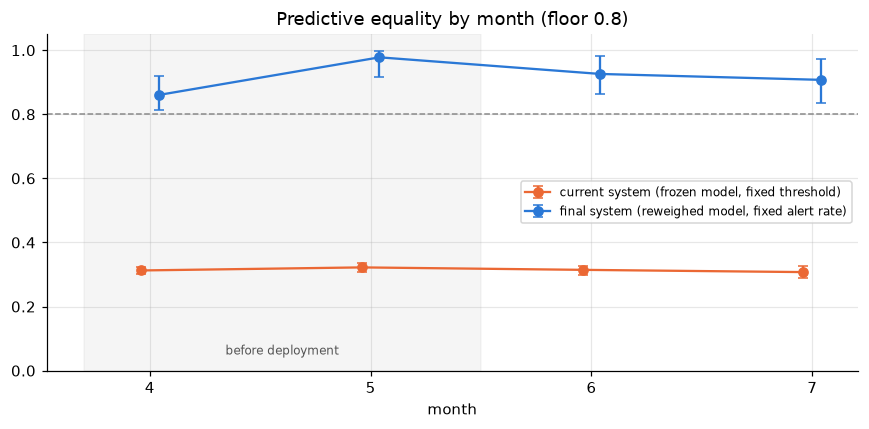

In [28]:
MONITOR_MONTHS = BASE_SCORE_MONTHS
PRE_DEPLOYMENT_MONTHS = VALIDATION_MONTHS + CALIBRATION_MONTHS
rows = []
for month in MONITOR_MONTHS:
    part = base_scores[base_scores['month'] == month].reset_index(drop=True)
    y, old = part['y_true'].to_numpy(), part['age_50_plus'].to_numpy()
    flags = {n: system_flags(n, part) for n in ('current', 'final')}
    res = evaluate_flags(y, old, flags, n_resamples=300)
    for n in ('current', 'final'):
        iv = with_interval(res, [n], 'predictive equality').iloc[0]
        model, rule = SYSTEMS[n]
        s0 = part[f'{model}_seed{DEPLOYED_SEED}'].to_numpy()
        rows.append({'month': month, 'system': n, 'predictive equality': iv['estimate'], 'CI low': iv['CI low'], 'CI high': iv['CI high'],
                     'FPR': res[n].loc[0, 'FPR'], 'alert rate': res[n].loc[0, 'alert rate'], 'recall': res[n].loc[0, 'recall'],
                     'score cut (seed 0)': s0[flags[n][DEPLOYED_SEED]].min()})
monitor = pd.DataFrame(rows)

rows = []
for n in ('current', 'final'):
    sub = monitor[monitor['system'] == n].set_index('month')
    level = sub.loc[PRE_DEPLOYMENT_MONTHS, 'predictive equality'].mean()
    for month in MONITOR_MONTHS:
        r = sub.loc[month]
        rows.append({'system': n, 'month': month, 'role': 'before deployment' if month in PRE_DEPLOYMENT_MONTHS else 'deployed',
                     'PE': round(r['predictive equality'], 3), 'PE before deployment': round(level, 3),
                     f'floor (PE < {FOUR_FIFTHS})': 'ACT' if r['predictive equality'] < FOUR_FIFTHS else 'ok',
                     f'drop (more than {MONITOR_DROP} below)': '-' if month in PRE_DEPLOYMENT_MONTHS else ('ACT' if r['predictive equality'] < level - MONITOR_DROP else 'ok'),
                     'FPR': round(r['FPR'], 4), 'alert rate': round(r['alert rate'], 4), 'score cut (seed 0)': round(r['score cut (seed 0)'], 4)})
display(pd.DataFrame(rows).set_index(['system', 'month']))

fig, ax = plt.subplots(figsize=(8, 4))
for k, (n, colour) in enumerate((('current', ORANGE), ('final', BLUE))):
    sub = monitor[monitor['system'] == n]
    x = sub['month'] + (k - 0.5) * 0.08
    ax.errorbar(x, sub['predictive equality'], yerr=[sub['predictive equality'] - sub['CI low'], sub['CI high'] - sub['predictive equality']],
                fmt='o-', color=colour, markersize=6, capsize=3, linewidth=1.5, label=LABELS[n])
ax.axhline(FOUR_FIFTHS, color=GREY, linestyle='--', linewidth=1)
ax.axvspan(3.7, 5.5, color=GREY, alpha=0.08)
ax.text(4.6, 0.05, 'before deployment', ha='center', fontsize=8, color='#555555')
ax.set_xticks(MONITOR_MONTHS)
ax.set_xlabel('month')
ax.set_ylim(0, 1.05)
ax.set_title('Predictive equality by month (floor 0.8)')
ax.legend(loc='center right', fontsize=8)
plt.tight_layout()
plt.show()

**Findings**

- **The final system passes every month**: predictive equality 0.926 and 0.907 on the deployed months 6-7, above the floor and within 0.04 of its level before deployment (0.919). The current system is below the floor in every month, which is the finding of notebook 06, not a monitoring failure.
- **One month before deployment was weaker** (month 4: 0.860, against 0.978 on month 5). Both are above the floor; notebook 06 (section 11.2) measured a noise of 0.04 for one month, so swings of this size are expected.
- **The fixed alert rate absorbs drift.** The score cut it implies moves from 0.576 (month 4) to 0.483-0.512 (months 5-7), while the FPR stays at 4.8-5.0%; the current fixed threshold let the FPR swing from 4.7% to 7.7% (and its alert rate from 5.4% to 8.4%) over the same months. A large move of the implied cut is the signal to re-check the alert rate.

## **13. Summary**

**The recommended system** is notebook 02's XGBoost recipe retrained with reweighing (Kamiran and Calders weights on age 50+), a Platt calibrator from month 5, a fixed alert rate of 5.55% set on month 5, and a review stage that sends the 50% least-sure alerts to the 10 lowest-cost analysts with history predictive equality of at least 0.8.

**Against the current system, on the Base test months (mean over 5 seeds, 95% intervals):**

| | Current system | Final system |
|---|---|---|
| Recall | 0.562 (0.544-0.579) | 0.520 (0.502-0.537) |
| FPR / alert rate | 5.3% / 6.0% | 4.9% / 5.55% |
| Precision | 0.131 | 0.132 |
| FPR 50+ / under 50 | 12.7% / 3.9% | 5.3% / 4.8% |
| Predictive equality | 0.307 (0.296-0.318) | **0.916** (0.872-0.959) |
| Equal opportunity | 0.699 | 0.961 |
| Cost per 10,000 (R = 10) | 1,139 | 1,155 (+16, +1 to +31) |
| Predictive equality on all 6 BAF datasets | 0.31 | 0.90-0.92 |
| Review stage, FiFAR month 7, half capacity: cost per 1,000 alerts / predictive equality | 510 / 0.726 | 621 / 0.792 |

**Answers to the project's questions:**
1. **Performance.** The final system catches 52% of fraud while flagging 5% of genuine applicants, 4 points less than the current system, of which 1.7 points come from flagging fewer applications and 2.5 points are the price of fairness. Precision is unchanged.
2. **Fairness.** The age gap is closed (0.31 to 0.92) on Base, in both test months and on every BAF variant, and equal opportunity rises with it. Housing status BA (0.09) is not repaired and remains the main open fairness issue.
3. **Interpretability.** The final model relies on the same features as the frozen one (rank correlation 0.995), so notebook 05's explanations carry over. Reweighing works by turning `customer_age` into a correction that offsets its proxies, not by removing age (section 10).
4. **Robustness.** Unlike the current fixed threshold, the alert rate keeps the FPR at 4.8-5.1% and the workload fixed on every month and every variant. Its weak point is a rise in fraud (recall 0.45 at 5% fraud), so it must be monitored and re-set.
5. **Realistic fraud rates.** False alarms do not rise as a rate (FPR about 5%), but per fraud caught they do: about 9.5 at 1% fraud and about 100 at 0.1%, for both systems.
6. **Limited review capacity.** Reviewing the least-sure half of the alerts with a fair analyst pool lifts recall on the alerts to 0.91 and predictive equality to 0.79, for 22% more cost than notebook 03's policy; 60% capacity reaches 0.8.

**What the system does not solve, and how far the evidence goes (section 11):**
- The probabilities are not calibrated within age groups (50+: observed / expected 2.13), so they should not be shown to reviewers as an individual's risk.
- The review stage was tested on Feedzai's alerts (63% of our alerts are among them), with synthetic analysts.
- Two method choices (the alert rate, the fair pool) were made in notebooks that had seen the test months; their values were set on month 5 and the history months. A new month of data is the real test.
- Neutralising the higher fraud rate of older applicants is a value judgement, which the system's owners must approve (notebook 06, section 11.3).